# Squares in Squares — Contact Atlas

A research-informed, resumable competition solver for all **1,000 puzzles**.
It combines a frozen public witness library, certified per-puzzle merging,
construction propagation, bounded contact-choice MILP, and a portfolio of
free-angle local searches. **Lower score is better.**

**Measured offline starting score: 22.333522251194**, with all
500,500 CSV rows accepted by the metric snapshot from the supplied notebook.
The supplied Neighbour Transfer notebook reports **22.298183371701** after
merging its attached public outputs. Its stronger full submission is **not**
embedded in the uploaded notebook; its compressed replay covers only selected
puzzles. This notebook automatically attempts to obtain public CSV outputs on
Kaggle and also scans attached CSVs. Those can make the starting bank stronger.

No first-place or new-record claim is made. Stochastic search must be measured
against the best input actually loaded. The final cells report that comparison
and write `submission.csv`, `submission_sources.csv`, `validation.json`,
`input_manifest.json`, and resumable `sis_run/` checkpoints.

## Run it

On Kaggle, import this notebook, attach the competition, and preferably attach
the output of [Neighbour Transfer + Squeeze](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-neighbour-transfer-squeeze)
and other strong public notebooks. Enable Internet to use the optional public
output refresh. **CPU is sufficient**; this implementation uses Numba when
available and SciPy HiGHS. A GPU is not used by this version.

Default search budget is **7,200 seconds**, followed by full validation.
Change `SEARCH_SECONDS` to 120 for a quick experiment, 0 for merge/replay only,
or a larger value for a longer campaign. Keep the `sis_run` directory to resume.
For a new independent campaign, change `RUN_SEED` and use a new `RUN_DIR`.
The search budget excludes input certification and final certification.

Input CSVs are data. This notebook does **not** execute code from downloaded
notebooks or follow instructions inside attachments. It does not upload a
Kaggle submission, accept competition rules, or require a Kaggle API token
embedded in its source.

## What the research changes

| Evidence | Useful consequence implemented here | Limit |
|---|---|---|
| [Friedman, DS7](https://erich-friedman.github.io/papers/squares/squares.html) | Reuse structured witnesses; propagate by deletion and L-shaped borders. A gain at one count may improve other counts. | Historical record tables are not today's leaderboard. |
| [Gensane & Ryckelynck, 2005](https://doi.org/10.1007/s00454-004-1129-z) | Jointly vary centres and angles, with compression and perturbation. | Only the publisher abstract was accessible; this is not a reproduction of their implementation. |
| [Addis, Locatelli & Schoen, basin hopping](https://optimization-online.org/wp-content/uploads/2005/10/1229.pdf) | Perturb, fully relax, then compare endpoints; retain several feasible basins for exploration. | Their experiments concern disks. Transfer to freely rotating squares is a heuristic. |
| [Cassioli & Locatelli, 2010](https://optimization-online.org/wp-content/uploads/2010/06/2637.pdf) | Include collective and combinatorial perturbations rather than only independent noise. | The paper's tested rectangle model uses discrete orientations; our angle search is continuous. |
| [Soft-to-Rigid, 2026 preprint](https://arxiv.org/abs/2610.14463) | Add an orientation-support continuation arm, then return to exact square SAT. | Our intermediate four-axis support surrogate is **not** the paper's exact rounded-polygon distance model. It has no feasibility authority. |
| [Evan Daniel's exact catalogue](https://github.com/evand/square-packing/tree/6067db5bf4d41dab7f0e1475e9fa845c0c6d2133/search/exact/batch/certs) and [Francisco Couzo's reviewed catalogue](https://github.com/franciscouzo/square-packing/tree/1c1715399709bc955e9b402947ab8b52bbacdfc3/certificates/best) | Start from real coordinate witnesses instead of rediscovering every packing. | Converting rational rotations to decimal angles requires validation of the submitted coordinates. |
| Supplied Neighbour Transfer + Squeeze notebook | Public layouts complement one another; precise admission and CSV parsing matter as much as tiny floating gains. | Its printed score is a report, not a score obtained in this development run. |

[The official metric](https://www.kaggle.com/code/metric/squares-in-squares)
uses $\sum_{n=1}^{1000}(L_n/\sqrt n-1)$. A side improvement $\Delta L$ at
puzzle $n$ is worth $\Delta L/\sqrt n$. Our scheduler estimates additional
benefit from border descendants and updates operator rewards using **certified
aggregate score gain per second**. This is a budget heuristic, not a prediction
of the unknown optimum.

The decision to combine these components is an engineering inference from the
sources and attachment audit. It is not a claim that this combination is new
in the literature. Large asymptotic packing theorems do not by themselves give
competitive finite coordinates for $n\le1000$; actual witnesses and measured
local improvements are the relevant deliverables.

## Geometry and search

Let $u_i=(\cos\theta_i,\sin\theta_i)$ and
$v_i=(-\sin\theta_i,\cos\theta_i)$. For a pair $(i,j)$ set
$\Delta=\theta_j-\theta_i$ and

$$r_{ij}=\tfrac12(1+|\cos\Delta|+|\sin\Delta|),\qquad
g_{ij}=\max_{a\in\{u_i,v_i,u_j,v_j\}}|(p_j-p_i)\cdot a|-r_{ij}.$$

The unit squares have disjoint interiors exactly when $g_{ij}\ge0$.
Squared negative gaps plus squared wall violations supply the local search
objective. Analytic gradients feed L-BFGS-B. The spatial cell list is rebuilt
at **every objective evaluation**, so squares crossing a cell boundary cannot
silently lose a collision constraint.

At fixed angles and fixed separating choices, compaction is a sparse LP.
`contact_branch` lets selected nearby pairs choose between two separating
axes using binary variables. Its big-M values follow from the actual centre
trust bounds. Distant pairs are omitted only when the entire trust box keeps
them beyond the circumdiameter $\sqrt2$. Global SAT and the official metric
still check every proposed improvement.

The operator portfolio includes LP/free-angle polishing, contact branching,
neighbour deletion, collective stress-guided moves, seam shifts, angle changes,
void reinsertion, support continuation, and whole-layout rotation. A small
pool can keep worse feasible endpoints to explore another basin. Only a
strictly better **officially feasible** pose can replace a submitted incumbent.

A uniform dilation opens tiny contacts by scaling centres, never unit square
side lengths. Large overlaps are rejected. Exact half-integer grids remain
available for every puzzle, including zero-score perfect squares. Proven
elementary cases are excluded from wasteful search; recent unreviewed claims
of optimality are not used as filters.

In [1]:
import os, sys, json, time, math, hashlib, base64, lzma, io, subprocess
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
os.chdir(ROOT)
RUN_DIR = Path(os.environ.get('SIS_RUN_DIR', 'sis_run'))
RUN_DIR.mkdir(parents=True, exist_ok=True)
SEARCH_SECONDS = int(os.environ.get('SIS_SEARCH_SECONDS', '7200'))
RUN_SEED = int(os.environ.get('SIS_RUN_SEED', '20261026'))
CERT_WORKERS = int(os.environ.get('SIS_CERT_WORKERS', str(min(4, os.cpu_count() or 1))))
FETCH_PUBLIC = os.environ.get('SIS_FETCH_PUBLIC', '1' if Path('/kaggle/input').exists() else '0') == '1'
INPUT_ROOT = Path(os.environ.get('SIS_INPUT_ROOT', '/kaggle/input'))
MAX_JOBS = int(os.environ['SIS_MAX_JOBS']) if 'SIS_MAX_JOBS' in os.environ else None
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(key, '1')
print(dict(search_seconds=SEARCH_SECONDS, seed=RUN_SEED, certification_workers=CERT_WORKERS,
           refresh_public=FETCH_PUBLIC, run_dir=str(RUN_DIR)))

{'search_seconds': 120, 'seed': 20261026, 'certification_workers': 2, 'refresh_public': False, 'run_dir': 'sis_run'}


## Unchanged metric snapshot

The following cell writes the metric supplied in the Neighbour Transfer
attachment **byte for byte**. Its SHA-256 is checked before import. This is
a frozen reference, not a claim to have fetched Kaggle's current source.
Recheck organizer metric changes before a serious campaign.

The engine supplies a narrow mpmath 1.3 compatibility adapter for the exact
integer `man` and `exp` properties used in formatting. It does not change
overlap predicates, precision escalation, scoring, or tolerances. mpmath 1.4
works directly. No dependency installation is required on normal Kaggle images.

In [2]:
METRIC_SOURCE = '"""Metric for the "Packing N Unit Squares into the Smallest Square" competition.\n\nParticipants submit packings of n unit squares (n=1..1000) inside a bounding\nsquare.  Each square is specified by its center (x, y) and rotation angle.\nCoordinates must be plain decimal literals, optionally in scientific notation\n(e.g. ``2.70710678118654752440`` or ``1.5e-3``).  Symbolic / closed-form\nexpressions are not accepted -- submit their decimal expansion instead, at as\nmany digits as you like.\n\nScoring\n-------\nFor each puzzle n the bounding side length L is measured\ntranslation-invariantly as ``max(max_x - min_x, max_y - min_y)`` over all\ncorners.  The per-puzzle score is the excess over the area lower bound\n\n    score(n) = L / sqrt(n) - 1\n\nwhich is 0.0 exactly when the packing achieves the area lower bound (only\npossible for perfect squares packed on the grid) and grows above 0 as the\nbounding square wastes area.  **Lower is better**; total score is the sum\nacross n=1..N.\n\n+-------------------+---------------------------------------------------------+\n| Condition         | Score                                                   |\n+===================+=========================================================+\n| feasible packing  | L / sqrt(n) - 1     (>= 0 always)                       |\n+-------------------+---------------------------------------------------------+\n| infeasible/invalid| L_0 / sqrt(n) - 1   (grid ceiling — no worse than       |\n|                   |                      submitting the trivial grid)       |\n+-------------------+---------------------------------------------------------+\n\nFor reference: ``L_B = sqrt(n)`` is the area lower bound and\n``L_0 = ceil(sqrt(n))`` is the trivial grid packing.  The best-known side\nlength plays no part -- beating a record just yields a smaller excess -- so\nthis metric reads no baseline values at all.\n\nFeasibility is checked with interval arithmetic (mpmath) at escalating\nprecision to certify that no two squares overlap.\n\nKaggle entry point\n------------------\n``score(solution, submission, row_id_column_name)`` — called by the Kaggle\nbackend.  ``solution`` is a DataFrame loaded from ``solution.csv``; only its\n``n`` column is read, to fix which puzzles are scored (and which absent ones\nare charged the grid ceiling).  ``submission`` is the participant CSV with\ncolumns ``n, square_id, x, y, angle``.\n\nAs a side effect it writes ``submission_details.csv``, one row per puzzle with\ncolumns ``n`` and ``L``::\n\n    n,L\n    1,1.00000000000000000000000000000000000000000000000000\n    2,2.00000000000000000000000000000000000000000000000000\n    ...\n\n``L`` is the measured bounding side for puzzle n -- not the per-puzzle score --\nwritten with exactly 50 digits after the decimal point.  Those digits are\nsignificant: L is measured in ``L_DPS``-digit mpmath arithmetic straight from\nthe submitted decimal strings, not from a double.  Puzzles with no accepted L\n(absent from the submission, unparseable, failing column validation, or\nrejected as infeasible) are written as zero.\n"""\n\nimport contextlib\nimport csv\nimport io\nimport math\nimport multiprocessing\nimport re\nfrom collections import defaultdict\nfrom collections.abc import Callable, Sequence\nfrom dataclasses import dataclass, field\nfrom fractions import Fraction\nfrom pathlib import Path\n\nimport mpmath\nimport pandas as pd\n\n# ---------------------------------------------------------------------------\n# interval\n# ---------------------------------------------------------------------------\n\nIVal = mpmath.ctx_iv.ivmpf\n\n# Working precision for the (non-interval) measurement of the bounding side L,\n# and the number of digits after the decimal point written for it in\n# submission_details.csv.  The margin between the two keeps every written digit\n# correct: the only rounding is in the trig of the corner computation, tens of\n# digits below the last digit reported.\nL_DPS = 60\nL_DECIMALS = 50\n\n\n@contextlib.contextmanager\ndef working_dps(dps: int):\n    """Run a block with both mpmath contexts at ``dps`` digits, then restore them.\n\n    ``mpmath.iv`` carries its own precision, independent of ``mpmath.mp``:\n    setting only ``mpmath.mp.dps`` leaves every interval operation at the\n    default 53 bits, which caps what a contact can be certified to at ~1e-13 no\n    matter how far the escalation sequence climbs.  Both contexts are set here\n    because the interval work is interleaved with plain ``mp`` arithmetic.\n\n    >>> with working_dps(500):\n    ...     width = mpmath.mpf(mpmath.iv.mpf(\'0.1\').delta)\n    >>> width < mpmath.mpf(10) ** -500\n    True\n    """\n    old_iv_dps = mpmath.iv.dps\n    old_mp_dps = mpmath.mp.dps\n    try:\n        mpmath.iv.dps = dps\n        mpmath.mp.dps = dps\n        yield\n    finally:\n        mpmath.iv.dps = old_iv_dps\n        mpmath.mp.dps = old_mp_dps\n\n\ndef make_interval(value: str, dps: int = 50) -> IVal:\n    with working_dps(dps):\n        return mpmath.iv.mpf(value)\n\n\ndef iv_cos(x: IVal) -> IVal:\n    return mpmath.iv.cos(x)\n\n\ndef iv_sin(x: IVal) -> IVal:\n    return mpmath.iv.sin(x)\n\n\n_ESCALATION_SEQUENCE = [50, 100, 200, 500]\n\n\ndef escalate(\n    fn: Callable[[int], bool | None],\n    max_dps: int = 500,\n    start_dps: int = 50,\n) -> bool | None:\n    for dps in _ESCALATION_SEQUENCE:\n        if dps < start_dps:\n            continue\n        if dps > max_dps:\n            break\n        result = fn(dps)\n        if result is not None:\n            return result\n    return None\n\n\ndef iv_le(a: IVal, b: IVal) -> bool | None:\n    """Certified less-or-equal: True if a <= b, False if a > b, None if undecided.\n\n    Comparing two overlapping intervals is indeterminate.  mpmath 1.3 reports\n    that as None, 1.4 raises ValueError; both mean "undecided" here.\n    """\n    try:\n        return a <= b\n    except ValueError:\n        return None\n\n\ndef iv_min(values: Sequence[IVal]) -> IVal:\n    """Interval extension of ``min``: the tightest interval containing the true minimum.\n\n    Comparison operators are useless for this -- two overlapping intervals have\n    no determinate order -- so take it endpoint-wise instead.  min of the lower\n    bounds is a lower bound on the true min, and min of the upper bounds is an\n    upper bound on it, whichever element turns out to be smallest.\n    """\n    return mpmath.iv.mpf([min(v.a for v in values), min(v.b for v in values)])\n\n\ndef iv_max(values: Sequence[IVal]) -> IVal:\n    """Interval extension of ``max``. See :func:`iv_min`."""\n    return mpmath.iv.mpf([max(v.a for v in values), max(v.b for v in values)])\n\n\n# ---------------------------------------------------------------------------\n# parser\n# ---------------------------------------------------------------------------\n\n# Bounds the cost of parsing one coordinate.  Far above any useful precision\n# (L is reported to 50 decimals), so no honest submission comes near it.\n_MAX_LITERAL_CHARS = 1000\n\n_DECIMAL_RE = re.compile(r\'^[+-]?(\\d+\\.?\\d*|\\.\\d+)([eE][+-]?\\d+)?$\')\n\n\ndef _is_decimal(s: str) -> bool:\n    return len(s) <= _MAX_LITERAL_CHARS and bool(_DECIMAL_RE.match(s.strip()))\n\n\ndef _check_decimal(s: str) -> str:\n    """Return the stripped literal, or raise if it is not a plain decimal.\n\n    >>> _check_decimal(" 2.70710678118654752440 ")\n    \'2.70710678118654752440\'\n    >>> _check_decimal("1.5e-3")\n    \'1.5e-3\'\n    >>> _check_decimal("1 + sqrt(2)")\n    Traceback (most recent call last):\n        ...\n    ValueError: not a decimal number: \'1 + sqrt(2)\'\n    """\n    s = s.strip()\n    if not _is_decimal(s):\n        shown = s if len(s) <= 40 else s[:40] + \'...\'\n        raise ValueError(f\'not a decimal number: {shown!r}\')\n    return s\n\n\ndef parse_value(s: str, dps: int = 50) -> IVal:\n    """Parse a decimal literal into an enclosing interval at ``dps`` digits."""\n    return make_interval(_check_decimal(s), dps)\n\n\ndef parse_value_mp(s: str, dps: int = L_DPS) -> mpmath.mpf:\n    """Parse a decimal literal into an ``mpf`` at ``dps`` digits.\n\n    >>> mpmath.nstr(parse_value_mp("2.70710678118654752440"), 21, strip_zeros=False)\n    \'2.70710678118654752440\'\n    """\n    s = _check_decimal(s)\n    old_dps = mpmath.mp.dps\n    try:\n        mpmath.mp.dps = dps\n        return mpmath.mpf(s)\n    finally:\n        mpmath.mp.dps = old_dps\n\n\ndef parse_value_float(s: str) -> float:\n    """Parse a decimal literal to float.\n\n    >>> parse_value_float("3.5")\n    3.5\n    >>> parse_value_float("-2.5")\n    -2.5\n    >>> parse_value_float("1.5e-3")\n    0.0015\n\n    Values too large for a double are rejected rather than becoming ``inf``,\n    which would poison every downstream geometry check:\n\n    >>> parse_value_float("1e400")\n    Traceback (most recent call last):\n        ...\n    ValueError: value out of range for a double: \'1e400\'\n    """\n    s = _check_decimal(s)\n    value = float(s)\n    if not math.isfinite(value):\n        raise ValueError(f\'value out of range for a double: {s!r}\')\n    return value\n\n\n# ---------------------------------------------------------------------------\n# scoring\n# ---------------------------------------------------------------------------\n\n\ndef score_puzzle(n: int, s_certified: float) -> float:\n    """Score a single puzzle: L / sqrt(n) - 1 (lower is better).\n\n    Result is >= 0 for any feasible packing (equality only for perfect-square\n    grid packings).  The best-known side length s* plays no part: beating a\n    record simply yields a smaller excess.\n\n    Perfect-square grid packing scores 0 exactly:\n    >>> score_puzzle(4, 2.0)\n    0.0\n\n    Larger L → larger (worse) score:\n    >>> round(score_puzzle(5, 2.707), 6)\n    0.210607\n\n    Doubling L takes the score from 0 to 1:\n    >>> score_puzzle(4, 4.0)\n    1.0\n    """\n    L_B = math.sqrt(n)\n    return s_certified / L_B - 1.0\n\n\ndef infeasible_score(n: int) -> float:\n    """Penalty score for an infeasible / invalid submission for puzzle n.\n\n    Equal to submitting the trivial grid packing: L_0 / sqrt(n) - 1.\n    """\n    return math.ceil(math.sqrt(n)) / math.sqrt(n) - 1.0\n\n\n# ---------------------------------------------------------------------------\n# geometry\n# ---------------------------------------------------------------------------\n\n\n@dataclass\nclass Square:\n    x: float\n    y: float\n    angle: float\n    x_str: str = \'\'\n    y_str: str = \'\'\n    angle_str: str = \'\'\n    _corners_float: list[tuple[float, float]] = field(default_factory=list, repr=False)\n\n    def corners_float(self) -> list[tuple[float, float]]:\n        if not self._corners_float:\n            self._corners_float = compute_corners_float(self.x, self.y, self.angle)\n        return self._corners_float\n\n\ndef compute_corners_float(cx: float, cy: float, angle: float) -> list[tuple[float, float]]:\n    """Return the four corners of a unit square centered at (cx, cy) rotated by angle.\n\n    >>> corners = compute_corners_float(0.5, 0.5, 0.0)\n    >>> [(round(x, 1), round(y, 1)) for x, y in corners]\n    [(1.0, 1.0), (0.0, 1.0), (0.0, 0.0), (1.0, 0.0)]\n    """\n    c = math.cos(angle)\n    s = math.sin(angle)\n    h = 0.5\n    dx1, dy1 = h * c - h * s, h * s + h * c\n    dx2, dy2 = -h * c - h * s, -h * s + h * c\n    return [\n        (cx + dx1, cy + dy1),\n        (cx + dx2, cy + dy2),\n        (cx - dx1, cy - dy1),\n        (cx - dx2, cy - dy2),\n    ]\n\n\ndef compute_corners_mp(cx: mpmath.mpf, cy: mpmath.mpf, angle: mpmath.mpf) -> list[tuple[mpmath.mpf, mpmath.mpf]]:\n    """``compute_corners_float`` at the ambient ``mpmath.mp`` precision."""\n    c = mpmath.cos(angle)\n    s = mpmath.sin(angle)\n    h = mpmath.mpf(1) / 2\n    dx1, dy1 = h * c - h * s, h * s + h * c\n    dx2, dy2 = -h * c - h * s, -h * s + h * c\n    return [\n        (cx + dx1, cy + dy1),\n        (cx + dx2, cy + dy2),\n        (cx - dx1, cy - dy1),\n        (cx - dx2, cy - dy2),\n    ]\n\n\ndef measure_side_mp(squares: list[\'Square\'], dps: int = L_DPS) -> mpmath.mpf:\n    """Bounding side ``max(max_x - min_x, max_y - min_y)`` at ``dps`` digits.\n\n    Measured from the submitted decimal strings, so a packing whose coordinates\n    carry more than double precision keeps that precision in the reported L.\n\n    >>> unit = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")\n    >>> measure_side_mp([unit])\n    mpf(\'1.0\')\n    """\n    old_dps = mpmath.mp.dps\n    try:\n        mpmath.mp.dps = dps\n        xs: list[mpmath.mpf] = []\n        ys: list[mpmath.mpf] = []\n        for sq in squares:\n            corners = compute_corners_mp(\n                parse_value_mp(sq.x_str, dps),\n                parse_value_mp(sq.y_str, dps),\n                parse_value_mp(sq.angle_str, dps),\n            )\n            for x, y in corners:\n                xs.append(x)\n                ys.append(y)\n        return max(max(xs) - min(xs), max(ys) - min(ys))\n    finally:\n        mpmath.mp.dps = old_dps\n\n\ndef compute_corners_interval(cx_iv: IVal, cy_iv: IVal, angle_iv: IVal) -> list[tuple[IVal, IVal]]:\n    c = iv_cos(angle_iv)\n    s = iv_sin(angle_iv)\n    h = mpmath.iv.mpf(\'0.5\')\n    dx1, dy1 = h * c - h * s, h * s + h * c\n    dx2, dy2 = -h * c - h * s, -h * s + h * c\n    return [\n        (cx_iv + dx1, cy_iv + dy1),\n        (cx_iv + dx2, cy_iv + dy2),\n        (cx_iv - dx1, cy_iv - dy1),\n        (cx_iv - dx2, cy_iv - dy2),\n    ]\n\n\ndef compute_aabb(corners: list[tuple[float, float]]) -> tuple[float, float, float, float]:\n    xs = [c[0] for c in corners]\n    ys = [c[1] for c in corners]\n    return (min(xs), min(ys), max(xs), max(ys))\n\n\ndef aabb_overlap(\n    a: tuple[float, float, float, float],\n    b: tuple[float, float, float, float],\n) -> bool:\n    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])\n\n\ndef _project_corners_float(corners: list[tuple[float, float]], ax: float, ay: float) -> tuple[float, float]:\n    projs = [ax * cx + ay * cy for cx, cy in corners]\n    return (min(projs), max(projs))\n\n\ndef sat_check_float(sq1: Square, sq2: Square, undecided_tol: float = 1e-8) -> str:\n    """Check overlap between two unit squares using the Separating Axis Theorem.\n\n    Returns ``"separated"``, ``"overlapping"``, or ``"undecided"``.\n\n    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(5.0, 5.0, 0.0))\n    \'separated\'\n    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0))\n    \'overlapping\'\n    """\n    c1 = sq1.corners_float()\n    c2 = sq2.corners_float()\n\n    axes = _get_axes_float(sq1.angle, sq2.angle)\n\n    min_overlap = float(\'inf\')\n    for ax, ay in axes:\n        min1, max1 = _project_corners_float(c1, ax, ay)\n        min2, max2 = _project_corners_float(c2, ax, ay)\n        overlap = min(max1, max2) - max(min1, min2)\n        if overlap < -undecided_tol:\n            return \'separated\'\n        min_overlap = min(min_overlap, overlap)\n\n    if min_overlap > undecided_tol:\n        return \'overlapping\'\n    return \'undecided\'\n\n\ndef _get_axes_float(angle1: float, angle2: float) -> list[tuple[float, float]]:\n    c1, s1 = math.cos(angle1), math.sin(angle1)\n    c2, s2 = math.cos(angle2), math.sin(angle2)\n    return [(c1, s1), (-s1, c1), (c2, s2), (-s2, c2)]\n\n\ndef sat_check_interval(\n    sq1_corners: list[tuple[IVal, IVal]],\n    sq2_corners: list[tuple[IVal, IVal]],\n    angle1_iv: IVal,\n    angle2_iv: IVal,\n) -> bool | None:\n    c1_iv, s1_iv = iv_cos(angle1_iv), iv_sin(angle1_iv)\n    c2_iv, s2_iv = iv_cos(angle2_iv), iv_sin(angle2_iv)\n    axes = [(c1_iv, s1_iv), (-s1_iv, c1_iv), (c2_iv, s2_iv), (-s2_iv, c2_iv)]\n\n    has_undecided = False\n    for ax, ay in axes:\n        projs1 = [ax * cx + ay * cy for cx, cy in sq1_corners]\n        projs2 = [ax * cx + ay * cy for cx, cy in sq2_corners]\n\n        # Endpoint-wise, via iv_min/iv_max: ordering two overlapping intervals\n        # with < is indeterminate, and skipping the projections that compare\n        # indeterminately would narrow the span -- which shrinks the overlap and\n        # biases the test towards wrongly certifying a pair as separated.\n        min1, max1 = iv_min(projs1), iv_max(projs1)\n        min2, max2 = iv_min(projs2), iv_max(projs2)\n\n        overlap = iv_min([max1, max2]) - iv_max([min1, min2])\n        le_result = iv_le(overlap, mpmath.iv.mpf(\'0\'))\n        if le_result is True:\n            return True\n        if le_result is None:\n            has_undecided = True\n\n    if has_undecided:\n        return None\n    return False\n\n\ndef sort_and_sweep(squares: list[Square]) -> list[tuple[int, int]]:\n    n = len(squares)\n    if n <= 1:\n        return []\n\n    aabbs = []\n    for i, sq in enumerate(squares):\n        corners = sq.corners_float()\n        aabb = compute_aabb(corners)\n        aabbs.append((i, aabb))\n\n    aabbs.sort(key=lambda x: x[1][0])\n\n    pairs = []\n    for i_idx in range(n):\n        i, aabb_i = aabbs[i_idx]\n        for j_idx in range(i_idx + 1, n):\n            j, aabb_j = aabbs[j_idx]\n            if aabb_j[0] > aabb_i[2]:\n                break\n            if aabb_overlap(aabb_i, aabb_j):\n                pairs.append((i, j) if i < j else (j, i))\n\n    return pairs\n\n\ndef verify_puzzle(\n    squares: list[Square],\n) -> tuple[bool, str]:\n    """Check that no two squares overlap, using float SAT then interval arithmetic.\n\n    >>> s1 = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")\n    >>> s2 = Square(1.5, 0.5, 0.0, x_str="1.5", y_str="0.5", angle_str="0")\n    >>> verify_puzzle([s1, s2])\n    (True, \'feasible\')\n    >>> verify_puzzle([Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0)])\n    (False, \'Squares 0 and 1 overlap (float check)\')\n    """\n    pairs = sort_and_sweep(squares)\n    undecided_pairs = []\n    for i, j in pairs:\n        result = sat_check_float(squares[i], squares[j])\n        if result == \'overlapping\':\n            return (False, f\'Squares {i} and {j} overlap (float check)\')\n        if result == \'undecided\':\n            undecided_pairs.append((i, j))\n\n    if undecided_pairs:\n\n        def check_overlap_certified(dps: int) -> bool | None:\n            # The whole pair loop runs inside the precision context: parsing at dps\n            # digits is not enough, since every later interval operation widens its\n            # result to whatever precision mpmath.iv is set to at the time.\n            with working_dps(dps):\n                still_undecided = []\n                for i, j in undecided_pairs:\n                    sq_i, sq_j = squares[i], squares[j]\n                    cx_i = parse_value(sq_i.x_str, dps)\n                    cy_i = parse_value(sq_i.y_str, dps)\n                    ai = parse_value(sq_i.angle_str, dps)\n                    cx_j = parse_value(sq_j.x_str, dps)\n                    cy_j = parse_value(sq_j.y_str, dps)\n                    aj = parse_value(sq_j.angle_str, dps)\n                    corners_i = compute_corners_interval(cx_i, cy_i, ai)\n                    corners_j = compute_corners_interval(cx_j, cy_j, aj)\n                    result = sat_check_interval(corners_i, corners_j, ai, aj)\n                    if result is False:\n                        return False\n                    if result is None:\n                        still_undecided.append((i, j))\n                if still_undecided:\n                    return None\n                return True\n\n        result = escalate(check_overlap_certified)\n        if result is False:\n            return (False, \'Squares overlap (certified)\')\n        if result is None:\n            return (False, \'Overlap undecidable at max precision\')\n\n    return (True, \'feasible\')\n\n\n# ---------------------------------------------------------------------------\n# main / Kaggle entry point\n# ---------------------------------------------------------------------------\n\n\nclass ParticipantVisibleError(Exception):\n    pass\n\n\nMAX_N = 1000\nKAGGLE_CORES = 4\nMIN_PUZZLES_FOR_MP = 4\n\n\ndef _parse_submission_csv(text: str) -> dict[int, list[dict]]:\n    reader = csv.DictReader(io.StringIO(text))\n    required_cols = {\'n\', \'square_id\', \'x\', \'y\', \'angle\'}\n    if not required_cols.issubset(set(reader.fieldnames or [])):\n        missing = required_cols - set(reader.fieldnames or [])\n        raise ParticipantVisibleError(f\'Missing columns: {missing}\')\n\n    puzzles: dict[int, list[dict]] = defaultdict(list)\n    for row_num, row in enumerate(reader, start=2):\n        try:\n            n = int(row[\'n\'])\n        except (ValueError, TypeError):\n            raise ParticipantVisibleError(f\'Row {row_num}: invalid n value: {row["n"]!r}\')\n        if n < 1 or n > MAX_N:\n            raise ParticipantVisibleError(f\'Row {row_num}: n={n} out of range [1, {MAX_N}]\')\n        puzzles[n].append(row)\n\n    return dict(puzzles)\n\n\ndef _validate_puzzle(n: int, rows: list[dict]) -> str | None:\n    if len(rows) != n:\n        return f\'n={n}: expected {n} rows, got {len(rows)}\'\n\n    square_ids = set()\n    for row in rows:\n        try:\n            sid = int(row[\'square_id\'])\n        except (ValueError, TypeError):\n            return f\'n={n}: invalid square_id: {row["square_id"]!r}\'\n        square_ids.add(sid)\n\n    expected_ids = set(range(n))\n    if square_ids != expected_ids:\n        return f\'n={n}: square_ids should be 0..{n - 1}, got {sorted(square_ids)}\'\n\n    return None\n\n\ndef _build_squares(n: int, rows: list[dict]) -> tuple[list[Square], mpmath.mpf]:\n    rows_by_id = {int(r[\'square_id\']): r for r in rows}\n\n    squares = []\n    for sid in range(n):\n        row = rows_by_id[sid]\n        x_str = row[\'x\'].strip()\n        y_str = row[\'y\'].strip()\n        angle_str = row[\'angle\'].strip()\n\n        try:\n            x_f = parse_value_float(x_str)\n            y_f = parse_value_float(y_str)\n            angle_f = parse_value_float(angle_str)\n        except ValueError as e:\n            raise ParticipantVisibleError(f\'n={n}, square {sid}: cannot parse coordinates: {e}\')\n\n        squares.append(\n            Square(\n                x=x_f,\n                y=y_f,\n                angle=angle_f,\n                x_str=x_str,\n                y_str=y_str,\n                angle_str=angle_str,\n            )\n        )\n\n    return squares, measure_side_mp(squares)\n\n\ndef evaluate_single_puzzle(n: int, rows: list[dict]) -> tuple[int, float, str | None, str]:\n    """Evaluate one puzzle, returning ``(n, score, L, reason)``.\n\n    ``L`` is decimal text with ``L_DECIMALS`` digits after the point, and is\n    reported only for a packing that passed the feasibility check: an\n    unparseable, malformed, or overlapping puzzle gets None, so no L is\n    published for a packing the metric rejected.  Text rather than a float\n    because a double cannot hold those digits; the score itself is a double,\n    taken from the same high-precision measurement.\n    """\n    error = _validate_puzzle(n, rows)\n    if error:\n        return (n, infeasible_score(n), None, error)\n\n    try:\n        squares, s_mp = _build_squares(n, rows)\n    except ParticipantVisibleError as e:\n        return (n, infeasible_score(n), None, str(e))\n\n    feasible, reason = verify_puzzle(squares)\n    if not feasible:\n        return (n, infeasible_score(n), None, f\'infeasible: {reason}\')\n\n    puzzle_score = score_puzzle(n, float(s_mp))\n    return (n, puzzle_score, _format_detail(s_mp), \'ok\')\n\n\ndef _evaluate_puzzle_worker(args: tuple) -> tuple[int, float, str | None, str]:\n    n, rows = args\n    try:\n        return evaluate_single_puzzle(n, rows)\n    except Exception as e:  # noqa: BLE001 - one bad puzzle must not kill the pool\n        return (n, infeasible_score(n), None, f\'worker error: {e}\')\n\n\ndef _evaluate_puzzles_parallel(\n    puzzles: dict[int, list[dict]],\n    puzzle_ns: set[int],\n) -> tuple[float, list[tuple[int, float, str | None, str]]]:\n    """Score every n in ``puzzle_ns``; rows for any other n are ignored."""\n    work = [(n, rows) for n, rows in sorted(puzzles.items()) if n in puzzle_ns]\n\n    if not work:\n        results: list[tuple[int, float, str | None, str]] = []\n    elif len(work) < MIN_PUZZLES_FOR_MP:\n        results = [evaluate_single_puzzle(n, rows) for n, rows in work]\n    else:\n        with multiprocessing.Pool(processes=KAGGLE_CORES) as pool:\n            results = pool.map(_evaluate_puzzle_worker, work)\n\n    # Any scored n missing from the submission gets the grid-ceiling penalty\n    # (lower-is-better metric — otherwise omitting a puzzle would improve the\n    # total).\n    seen = {n for n, _, _, _ in results}\n    for n in puzzle_ns:\n        if n not in seen:\n            results.append((n, infeasible_score(n), None, \'missing from submission\'))\n    results.sort(key=lambda r: r[0])\n\n    total = sum(puzzle_score for _, puzzle_score, _, _ in results)\n    return total, results\n\n\ndef _format_detail(value: mpmath.mpf) -> str:\n    """Decimal text for one per-puzzle L: exactly ``L_DECIMALS`` digits after the point.\n\n    An ``mpf`` is a binary fraction (``man * 2**exp``), so it is converted\n    exactly to a ``Fraction`` and rounded once, half-to-even, at the last\n    written digit.  ``mpmath.nstr`` counts significant digits rather than\n    decimal places, and ``format(mpf, \'.50f\')`` needs mpmath >= 1.4, so neither\n    is usable here.\n\n    >>> _format_detail(mpmath.mpf(2))[:12]\n    \'2.0000000000\'\n    >>> len(_format_detail(mpmath.mpf(2)).split(\'.\')[1])\n    50\n    >>> _format_detail(parse_value_mp(\'1.41421356237309504880168872420969807856967187537695\'))\n    \'1.41421356237309504880168872420969807856967187537695\'\n    """\n    exact = Fraction(value.man) * Fraction(2) ** value.exp\n    scale = 10**L_DECIMALS\n    units = round(exact * scale)\n    sign = \'-\' if units < 0 else \'\'\n    whole, frac = divmod(abs(units), scale)\n    return f\'{sign}{whole}.{frac:0{L_DECIMALS}d}\'\n\n\ndef score(\n    solution: pd.DataFrame,\n    submission: pd.DataFrame,\n    row_id_column_name: str,\n) -> float:\n    """Kaggle entry point. Score a submission against the solution\'s puzzle set.\n\n    ``solution`` is read for one thing only: the set of n to score.  Everything\n    else about a puzzle -- best-known side length, proven-optimal flag, source\n    -- is irrelevant to ``L / sqrt(n) - 1``.\n\n    >>> import pandas as pd\n    >>> sol = pd.DataFrame({"id": [0], "n": [1]})\n    >>> sub = pd.DataFrame({"id": [0], "n": [1], "square_id": [0],\n    ...     "x": ["0.5"], "y": ["0.5"], "angle": ["0"]})\n    >>> score(sol, sub, "id")  # single unit square, L=1, L/sqrt(1) - 1 = 0.0\n    0.0\n    """\n    solution = solution.drop(columns=[row_id_column_name])\n    submission = submission.drop(columns=[row_id_column_name])\n\n    puzzle_ns = {int(n) for n in solution[\'n\']}\n\n    text = submission.to_csv(index=False)\n    puzzles = _parse_submission_csv(text)\n    total, results = _evaluate_puzzles_parallel(puzzles, puzzle_ns)\n\n    # L is the measured bounding side for puzzle n -- NOT the per-puzzle score\n    # L/sqrt(n) - 1.  Puzzles with no accepted L (missing from the submission,\n    # unparseable, failing column validation, or rejected as infeasible) keep\n    # the historical 0 placeholder: an L measured off an overlapping packing is\n    # not a real packing of n squares, and downstream harvesting treats every\n    # published L as attainable.  Values arrive here already rendered as decimal\n    # text with L_DECIMALS digits after the point; unlike a JSON float they are\n    # not re-serialized downstream, so all 50 digits reach the stored file\n    # verbatim.\n    result_map = {n: L_text for n, _, L_text, _ in results if L_text is not None}\n    zero = _format_detail(mpmath.mpf(0))\n\n    output_dir = Path(\'/kaggle/working\')\n    if not output_dir.is_dir():\n        output_dir = Path(\'.\')\n    with open(output_dir / \'submission_details.csv\', \'w\', newline=\'\') as f:\n        writer = csv.writer(f)\n        writer.writerow([\'n\', \'L\'])\n        for n in range(1, MAX_N + 1):\n            writer.writerow([n, result_map.get(n, zero)])\n\n    return float(total)'
Path('metric.py').write_text(METRIC_SOURCE, encoding='utf-8')
assert hashlib.sha256(Path('metric.py').read_bytes()).hexdigest() == 'fa0f8bd77c509735110fba881d3d73160a624d7fb4c309634e3ca6f065e6f7cb'

## Search implementation

This is the complete implementation, not a call to an external solver service.
All source is included for review and modification. The downloaded resources
in later cells are CSV data only.

In [3]:
ENGINE_SOURCE = r'''"""Squares in Squares: verified archive, SAT search, contact compaction, transfer.

Original implementation for this notebook. Mathematical methods and witness
credits are documented in its research cells. Metric code is a separate,
unchanged Apache-2.0 reference snapshot supplied in the user's attachment.
"""
from __future__ import annotations
import csv, hashlib, io, json, math, os, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
from dataclasses import dataclass
import numpy as np
import pandas as pd
from scipy.optimize import minimize, linprog, minimize_scalar, milp, Bounds, LinearConstraint
from scipy.spatial import cKDTree, ConvexHull
from scipy.sparse import coo_matrix
import mpmath
# The supplied metric formats exact mpf mantissa/exponent via the 1.4 API.
# On 1.3 expose the identical integer fields; no predicate or tolerance changes.
if not hasattr(mpmath.mpf(1),'man'):
    mpmath.mpf.man=property(lambda x:x._mpf_[1])
    mpmath.mpf.exp=property(lambda x:x._mpf_[2])
try:
    from numba import njit
    JIT = True
except ImportError:
    JIT = False
    def njit(*args, **kwargs):
        if args and callable(args[0]): return args[0]
        return lambda fn: fn

GAP = 2e-10
SQRT2 = math.sqrt(2)

def grid(n):
    k = math.isqrt(n-1)+1
    i = np.arange(n)
    return np.column_stack((i % k + .5, i // k + .5, np.zeros(n)))

def proven_lower(n):
    # Conservative published cases only: Friedman DS7, Nagamochi (2005),
    # and Bentz (2010). Recent unreviewed catalogue claims are not filters.
    k=math.isqrt(n-1)+1
    if n in (k*k,k*k-1,k*k-2):return float(k)
    special={5:2+math.sqrt(.5),6:3.,7:3.,8:3.,10:3+math.sqrt(.5),13:4.,46:7.}
    return special.get(n,math.sqrt(n))

def halfwidth(p):
    a = p[:,2]
    return .5*(np.abs(np.cos(a))+np.abs(np.sin(a)))

def side(p):
    h = halfwidth(p)
    return float(np.max((p[:,:2]+h[:,None]).max(0)-(p[:,:2]-h[:,None]).min(0)))

def normalize(p):
    p = np.asarray(p, dtype=np.float64).copy()
    # Avoid changing already valid angle decimals during ingestion.
    p[:,:2] -= (p[:,:2]-halfwidth(p)[:,None]).min(0)
    return p

def edges(p, radius=SQRT2+1e-8):
    return cKDTree(p[:,:2]).query_pairs(radius, output_type='ndarray').reshape(-1,2)

def pair_data(p, ij):
    i,j = ij.T
    c,s = np.cos(p[:,2]),np.sin(p[:,2])
    axes = np.stack((np.column_stack((c[i],s[i])),np.column_stack((-s[i],c[i])),
                     np.column_stack((c[j],s[j])),np.column_stack((-s[j],c[j]))),axis=1)
    d = p[j,:2]-p[i,:2]
    proj = np.einsum('ik,ijk->ij',d,axes)
    dt = p[j,2]-p[i,2]
    radius = .5*(1+np.abs(np.cos(dt))+np.abs(np.sin(dt)))
    return axes,proj,radius

def max_penetration(p):
    ij=edges(p)
    if not len(ij): return 0.
    _,z,r=pair_data(p,ij)
    return float(np.maximum(r-np.abs(z).max(1),0).max(initial=0))

def legalize(p, max_dilation=.025, gap=GAP):
    """Open every nearby SAT contact by scaling centres, never the unit squares.

    For a fixed orientation, separation along an axis scales linearly with the
    centre difference. Distant pairs cannot overlap (circumdiameter sqrt(2)),
    and dilation cannot create an overlap. Official certification remains final.
    """
    p=np.asarray(p,dtype=float).copy()
    if p.ndim!=2 or p.shape[1]!=3 or not len(p) or not np.isfinite(p).all():return None
    ij=edges(p)
    if len(ij):
        _,z,r=pair_data(p,ij);d=np.abs(z).max(1)
        if np.any(d<1e-13):return None
        factor=max(1.,float(((r+gap)/d).max()))
        if factor>1+max_dilation:return None
        ctr=p[:,:2].mean(0);p[:,:2]=ctr+(p[:,:2]-ctr)*factor
    return normalize(p)

def decimal_roundtrip(p):
    # Match pandas' default reader, not merely Python float(repr(x)).
    f=io.StringIO();np.savetxt(f,p,delimiter=',',fmt='%.17g')
    return pd.read_csv(io.StringIO(f.getvalue()),header=None).to_numpy(float)

def metric_job(job):
    import metric
    n,p=job
    rows=[dict(n=str(n),square_id=str(k),x=repr(float(x)),y=repr(float(y)),
               angle=repr(float(a))) for k,(x,y,a) in enumerate(p)]
    try:return metric.evaluate_single_puzzle(n,rows)
    except Exception as e:return n,float('inf'),None,f'{type(e).__name__}: {e}'

class Archive:
    """Only officially feasible decimal poses enter best; exploration is separate."""
    def __init__(self, max_n=1000, workdir='sis_run'):
        self.max_n=max_n;self.root=Path(workdir);self.root.mkdir(parents=True,exist_ok=True)
        self.best={n:grid(n) for n in range(1,max_n+1)}
        self.length={n:side(p) for n,p in self.best.items()}
        self.source={n:'exact grid' for n in self.best};self.events=[]
        self.cache={};self.checks={};self.started=time.monotonic()
        self.cache_metric_sha=hashlib.sha256(Path(__file__).with_name('metric.py').read_bytes()).hexdigest()
    def total(self):return sum(self.length[n]/math.sqrt(n)-1 for n in range(1,self.max_n+1))
    def consider(self,p,source,repair=True,certify=True):
        n=len(p)
        if n not in self.best:return False
        p=legalize(p) if repair else np.asarray(p,float).copy()
        if p is None:return False
        p=decimal_roundtrip(p)
        L=side(p)
        if L>=self.length[n]-5e-12:return False
        if not certify:raise ValueError('Archive admission requires certification')
        key=hashlib.sha256(p.astype('<f8').tobytes()).hexdigest()
        result=self.cache.get(key)
        if result is None:result=metric_job((n,p));self.cache[key]=result
        if result[3]!='ok':return False
        L=float(result[2])
        if L>=self.length[n]-5e-12:return False
        old=self.length[n];self.best[n]=p;self.length[n]=L;self.source[n]=source
        self.checks[n]=result
        e=dict(n=n,old_L=old,new_L=L,gain=(old-L)/math.sqrt(n),source=source,
               seconds=time.monotonic()-self.started)
        self.events.append(e)
        with (self.root/'improvements.jsonl').open('a') as f:f.write(json.dumps(e)+'\n')
        # One atomic checkpoint per improved puzzle; interrupted runs remain usable.
        tmp=self.root/f'candidate_{n}.tmp.npz';np.savez_compressed(tmp,p=p)
        os.replace(tmp,self.root/f'candidate_{n}.npz')
        return True
    def load_csv(self,path):
        count=0
        source_tag=f'CSV:{Path(path).name}:{hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]}'
        try:
            df=pd.read_csv(path)
            need={'id','n','square_id','x','y','angle'}
            if not need.issubset(df.columns) or df.id.duplicated().any():return 0
            if not np.isfinite(df[['n','square_id','x','y','angle']].to_numpy(float)).all():return 0
            if not np.equal(df.n,df.n.astype(int)).all():return 0
            for n,g in df.groupby('n',sort=True):
                n=int(n)
                if n not in self.best or len(g)!=n:continue
                g=g.sort_values('square_id')
                if not np.array_equal(g.square_id.to_numpy(),np.arange(n)):continue
                p=g[['x','y','angle']].to_numpy(float)
                # First preserve a source already valid at its exact decimals.
                if self.consider(p,source_tag,repair=False):count+=1
                elif side(p)<self.length[n]-5e-10:
                    count+=self.consider(p,source_tag+':repaired',repair=True)
        except (ValueError,KeyError,TypeError,pd.errors.ParserError) as e:
            print('Skipped malformed input',Path(path).name,type(e).__name__)
        return count
    def restore(self):
        for f in sorted(self.root.glob('candidate_*.npz')):
            with np.load(f,allow_pickle=False) as z:self.consider(z['p'],'checkpoint',repair=False)
    def save(self,name='checkpoint.npz'):
        tmp=self.root/(name+'.tmp.npz')
        np.savez_compressed(tmp,**{str(n):p for n,p in self.best.items()})
        os.replace(tmp,self.root/name)
    def export(self,path):
        path=Path(path);tmp=path.with_suffix('.tmp.csv')
        with tmp.open('w',newline='') as f:
            w=csv.writer(f);w.writerow(['id','n','square_id','x','y','angle']);idx=0
            for n in range(1,self.max_n+1):
                for k,(x,y,a) in enumerate(self.best[n]):
                    w.writerow([idx,n,k,repr(float(x)),repr(float(y)),repr(float(a))]);idx+=1
        os.replace(tmp,path)
        return path

def crop(p,n,mode=0):
    """Valid subsets with boundary removal; no geometric solver assumptions."""
    if n==len(p):return p.copy()
    p=normalize(p);h=halfwidth(p)
    lo=p[:,:2]-h[:,None];hi=p[:,:2]+h[:,None]
    if mode<4:
        corner=np.array([0 if mode&1 else hi[:,0].max(),0 if mode&2 else hi[:,1].max()])
        rank=np.maximum(np.abs(p[:,:2]-corner),0).max(1)
        return p[np.sort(np.argsort(rank,kind='stable')[:n])].copy()
    active=np.ones(len(p),bool)
    for _ in range(len(p)-n):
        ids=np.flatnonzero(active)
        extreme=set()
        for d in (0,1):
            extreme.add(int(ids[np.argmin(lo[ids,d])]))
            extreme.add(int(ids[np.argmax(hi[ids,d])]))
        best=None
        for i in sorted(extreme):
            keep=ids[ids!=i]
            spans=hi[keep].max(0)-lo[keep].min(0)
            key=(spans.max(),spans.sum(),i)
            if best is None or key<best[0]:best=(key,i)
        active[best[1]]=False
    return p[active].copy()

def add_border(p,j=1):
    p=normalize(p);L=side(p);step=1+GAP
    f=max(0,math.floor((L-GAP)/step));out=[p]
    for t in range(j):
        col=np.array([(L+GAP+t*step+.5,r*step+.5,0.) for r in range(f+j)])
        row=np.array([(r*step+.5,L+GAP+t*step+.5,0.) for r in range(f)])
        if len(col):out.append(col)
        if len(row):out.append(row)
    return np.vstack(out)

def tile(p,k=2):
    p=normalize(p);L=side(p)+GAP
    return np.vstack([p+np.array([a*L,b*L,0.]) for a in range(k) for b in range(k)])

def closure(archive,rounds=2,deadline=float('inf'),verbose=True):
    """Deletion, border insertion and tiling; all changes pass archive admission."""
    wins=0
    for depth in range(rounds):
        changed=0
        for n in sorted(archive.best,reverse=True):
            if time.monotonic()>deadline:return wins
            p=archive.best[n];L=archive.length[n]
            # Monotonic envelope. Deep crops are only useful if their parent's box wins.
            for target in range(n-1,max(0,n-5),-1):
                if L<archive.length[target]-5e-10:
                    q=min((crop(p,target,m) for m in (0,1,2,3,4)),key=side)
                    changed+=archive.consider(q,f'delete:{n}->{target}',repair=False)
            if L>=math.ceil(math.sqrt(n))-1e-8:continue
            for j in (1,2,3):
                q=add_border(p,j);m=len(q)
                if m>archive.max_n:break
                if side(q)<archive.length[m]-5e-10:
                    changed+=archive.consider(q,f'border:{n}+{j}',repair=False)
            if 4*n<=archive.max_n:
                q=tile(p)
                if side(q)<archive.length[4*n]-5e-10:
                    changed+=archive.consider(q,f'tile2:{n}',repair=False)
        wins+=changed
        if verbose:print(f'closure {depth+1}: {changed} accepted; total={archive.total():.12f}',flush=True)
        if not changed:break
    return wins

@njit(cache=True)
def _sgn(x):return 1. if x>0 else (-1. if x<0 else 0.)

@njit(cache=True)
def energy_gradient(z,n,target,hardness=1.):
    """Squared SAT penetration + walls, with a fresh cell list on EVERY call.

    hardness<1 interpolates support radii for exploration only. Intermediate
    shapes are a surrogate; at hardness=1 the four square axes are exact SAT.
    Cell width 1.5 exceeds the circumdiameter, so adjacent cells cover all pairs.
    """
    p=z.reshape(n,3);g=np.zeros_like(p);energy=0.
    c=np.cos(p[:,2]);s=np.sin(p[:,2])
    width=1.5
    xmin=np.min(p[:,0])-1e-8;ymin=np.min(p[:,1])-1e-8
    nx=int((np.max(p[:,0])-xmin)/width)+1;ny=int((np.max(p[:,1])-ymin)/width)+1
    # L-BFGS bounds keep this small, even when a trial temporarily leaves its box.
    head=np.full(nx*ny,-1,np.int64);nxt=np.full(n,-1,np.int64)
    for i in range(n):
        ix=int((p[i,0]-xmin)/width);iy=int((p[i,1]-ymin)/width);cell=ix+nx*iy
        nxt[i]=head[cell];head[cell]=i
    for i in range(n):
        h=.5*(1+hardness*(abs(c[i])+abs(s[i])-1))
        dh=.5*hardness*(-s[i]*_sgn(c[i])+c[i]*_sgn(s[i]))
        for d in range(2):
            low=h-p[i,d];high=p[i,d]+h-target
            if low>0:energy+=low*low;g[i,d]-=2*low;g[i,2]+=2*low*dh
            if high>0:energy+=high*high;g[i,d]+=2*high;g[i,2]+=2*high*dh
        ix=int((p[i,0]-xmin)/width);iy=int((p[i,1]-ymin)/width)
        for ax in range(max(0,ix-1),min(nx,ix+2)):
            for ay in range(max(0,iy-1),min(ny,iy+2)):
                j=head[ax+nx*ay]
                while j>=0:
                    if j>i:
                        dx=p[j,0]-p[i,0];dy=p[j,1]-p[i,1]
                        if dx*dx+dy*dy<2.00000001:
                            ux=np.array([c[i],-s[i],c[j],-s[j]])
                            uy=np.array([s[i],c[i],s[j],c[j]])
                            best=-1.;k=0;v=0.
                            for a in range(4):
                                vv=dx*ux[a]+dy*uy[a]
                                if abs(vv)>best:best=abs(vv);k=a;v=vv
                            delta=p[j,2]-p[i,2];cd=math.cos(delta);sd=math.sin(delta)
                            rad=1+.5*hardness*(abs(cd)+abs(sd)-1)
                            overlap=rad-best
                            if overlap>0:
                                energy+=overlap*overlap;w=2*overlap
                                vx=_sgn(v)*ux[k];vy=_sgn(v)*uy[k]
                                g[i,0]+=w*vx;g[i,1]+=w*vy;g[j,0]-=w*vx;g[j,1]-=w*vy
                                dr=.5*hardness*(-sd*_sgn(cd)+cd*_sgn(sd))
                                g[i,2]-=w*dr;g[j,2]+=w*dr
                                rot=dx*(-vy)+dy*vx
                                if k<2:g[i,2]-=w*rot
                                else:g[j,2]-=w*rot
                    j=nxt[j]
    return energy,g.ravel()

def relax(p,target,iterations=300,hardness=1.,deadline=float('inf')):
    p=normalize(p);n=len(p);bounds=[]
    for x,y,a in p:bounds.extend([(-1.,target+1.),(-1.,target+1.),(a-math.pi/3,a+math.pi/3)])
    def fg(z):
        if time.monotonic()>deadline:raise TimeoutError
        return energy_gradient(z,n,target,hardness)
    try:
        fit=minimize(fg,p.ravel(),method='L-BFGS-B',jac=True,bounds=bounds,
                     options=dict(maxiter=iterations,ftol=1e-18,gtol=1e-10,maxls=35,maxcor=20))
        return fit.x.reshape(n,3),float(fit.fun)
    except TimeoutError:return p,float('inf')

def rigid_rotate(p):
    """Search whole-layout rotation, including square-box width/height crossings."""
    p=p.copy();ctr=p[:,:2].mean(0);p[:,:2]-=ctr
    def at(a):
        q=p.copy();c,s=math.cos(a),math.sin(a)
        q[:,:2]=p[:,:2]@np.array([[c,s],[-s,c]]);q[:,2]+=a
        return q
    grid_angles=np.linspace(-math.pi/4,math.pi/4,65);ls=[side(at(a)) for a in grid_angles]
    best=(side(p),0.)
    for k in np.argsort(ls)[:4]:
        fit=minimize_scalar(lambda a:side(at(a)),bounds=(grid_angles[max(0,k-1)],grid_angles[min(64,k+1)]),
                            method='bounded',options={'xatol':1e-13})
        if fit.fun<best[0]:best=(fit.fun,fit.x)
    return normalize(at(best[1]))

def fixed_lp(p,trust=.18,seed=0,time_limit=2.):
    """Solve one separation cell at fixed angles using sparse HiGHS LP.

    A pair omitted at the old centres must remain farther than sqrt(2) after
    both centres move anywhere in their trust boxes. All trial solutions are
    checked globally, so no stale-neighbour assumption reaches the archive.
    """
    p=normalize(p);n=len(p);L=side(p);h=halfwidth(p)
    ij=edges(p,SQRT2+2*SQRT2*trust+1e-7)
    axes,z,r=pair_data(p,ij);rng=np.random.default_rng(seed)
    k=(np.abs(z)+rng.uniform(-1e-10,1e-10,z.shape)).argmax(1);rr=np.arange(len(ij))
    v=axes[rr,k]*np.where(z[rr,k]>=0,1.,-1.)[:,None];i,j=ij.T
    rows=[];cols=[];data=[];rhs=[]
    for e,(ii,jj) in enumerate(ij):
        rows.extend([e]*4);cols.extend([2*ii,2*ii+1,2*jj,2*jj+1]);data.extend([*v[e],*-v[e]])
        rhs.append(-r[e]-GAP)
    offset=len(rhs)
    for ii in range(n):
        for d in range(2):
            row=offset+2*ii+d;rows.extend([row,row]);cols.extend([2*ii+d,2*n]);data.extend([1.,-1.]);rhs.append(-h[ii])
    A=coo_matrix((data,(rows,cols)),shape=(len(rhs),2*n+1)).tocsr()
    objective=np.zeros(2*n+1);objective[-1]=1
    bounds=[(max(h[ii],p[ii,d]-trust),max(h[ii],p[ii,d]+trust)) for ii in range(n) for d in range(2)]
    bounds.append((math.sqrt(n),L+1e-6))
    fit=linprog(objective,A_ub=A,b_ub=rhs,bounds=bounds,method='highs',
                options=dict(time_limit=max(.05,time_limit),primal_feasibility_tolerance=1e-9))
    if not fit.success:return p,None
    q=p.copy();q[:,:2]=fit.x[:-1].reshape(n,2);q=legalize(q,max_dilation=.002)
    # LP shadow prices identify heavily loaded contacts for a collective move.
    stress=np.zeros(n)
    if hasattr(fit,'ineqlin'):
        load=np.abs(fit.ineqlin.marginals[:len(ij)]);np.add.at(stress,i,load);np.add.at(stress,j,load)
    return (q if q is not None and side(q)<L else p),stress

def contact_branch(p,trust=.22,branches=10,seed=0,time_limit=3.):
    """Change a few separation choices with an exact fixed-angle MILP.

    Each chosen pair has two possible separating axes and one binary choice.
    Big-M constants come from the actual coordinate trust bounds, not an
    arbitrary large number. Other pairs retain a separating branch. This is
    a bounded local combinatorial search, not a global optimality certificate.
    """
    p=normalize(p);n=len(p);L=side(p);h=halfwidth(p)
    ij=edges(p,SQRT2+2*SQRT2*trust+1e-7);axes,z,r=pair_data(p,ij)
    order=np.argsort(-np.abs(z),axis=1,kind='stable')
    # Aligned squares offer duplicate axes. Only geometrically distinct
    # alternatives capable of becoming feasible within the trust box matter.
    candidates=[]
    for row in range(len(ij)):
        k=order[row,0];v=axes[row,k]*np.sign(z[row,k])
        for kk in order[row,1:]:
            vv=axes[row,kk]*np.sign(z[row,kk])
            if abs(np.dot(v,vv))>.999999:continue
            reachable=abs(z[row,kk])+2*trust*np.abs(vv).sum()>=r[row]+GAP
            if reachable and abs(z[row,k])-r[row]<.12:
                candidates.append((abs(z[row,k])-abs(z[row,kk]),row,int(k),int(kk)))
            break
    if not candidates:return p
    rng=np.random.default_rng(seed);rng.shuffle(candidates)
    candidates.sort(key=lambda v:v[0]);selected={x[1]:x for x in candidates[:branches]}
    nv=2*n+1+len(selected);binary={row:2*n+1+k for k,row in enumerate(selected)}
    lower=np.empty(nv);upper=np.empty(nv)
    for i in range(n):
        for d in (0,1):lower[2*i+d]=max(h[i],p[i,d]-trust);upper[2*i+d]=max(lower[2*i+d],p[i,d]+trust)
    lower[2*n]=math.sqrt(n);upper[2*n]=L+1e-7
    lower[2*n+1:]=0;upper[2*n+1:]=1
    rr=[];cc=[];vv=[];rhs=[]
    def add(columns,values,b):
        row=len(rhs);rr.extend([row]*len(columns));cc.extend(columns);vv.extend(values);rhs.append(b)
    for row,(i,j) in enumerate(ij):
        opts=selected[row][2:] if row in selected else [int(order[row,0])]
        for option,k in enumerate(opts):
            v=axes[row,k]*np.where(z[row,k]>=0,1.,-1.)
            cols=[2*i,2*i+1,2*j,2*j+1];vals=[v[0],v[1],-v[0],-v[1]]
            bound=-r[row]-GAP
            if row in selected:
                # At option 0 active if b=0; option 1 active if b=1.
                max_lhs=sum(a*(upper[c] if a>=0 else lower[c]) for c,a in zip(cols,vals))
                M=max(0.,max_lhs-bound)+1e-9
                cols.append(binary[row]);vals.append(-M if option==0 else M)
                if option==1:bound+=M
            add(cols,vals,bound)
    for i in range(n):
        for d in (0,1):add([2*i+d,2*n],[1.,-1.],-h[i])
    A=coo_matrix((vv,(rr,cc)),shape=(len(rhs),nv)).tocsc()
    objective=np.zeros(nv);objective[2*n]=1
    integrality=np.zeros(nv,int);integrality[2*n+1:]=1
    fit=milp(objective,integrality=integrality,bounds=Bounds(lower,upper),
             constraints=LinearConstraint(A,-np.inf,np.array(rhs)),
             options=dict(time_limit=max(.05,time_limit),mip_rel_gap=1e-9))
    if fit.x is None:return p
    q=p.copy();q[:,:2]=fit.x[:2*n].reshape(n,2);q=legalize(q,max_dilation=.002)
    return q if q is not None and side(q)<L else p

def free_polish(p,steps=5,deadline=float('inf')):
    """Free-angle feasibility continuation followed by fixed-angle LP."""
    best=legalize(p)
    if best is None:return None
    step=.002
    for t in range(steps):
        if time.monotonic()>deadline:break
        q,_=relax(best,side(best)-step,iterations=350,deadline=deadline)
        q=legalize(q,max_dilation=.003)
        if q is not None and side(q)<side(best)-1e-10:best=q;step=min(.015,step*1.5)
        else:step*=.25
        if step<1e-7:break
    if time.monotonic()<deadline:
        q,_=fixed_lp(best,time_limit=min(1.,max(.05,deadline-time.monotonic())))
        if side(q)<side(best):best=q
    return best

def perturb(p,rng,mode,stress=None):
    q=normalize(p);L=side(q);n=len(q)
    if mode=='jitter':
        q[:,:2]+=rng.normal(0,.035,(n,2));q[:,2]+=rng.normal(0,.025,n)
    elif mode in ('cluster','stress'):
        weights=(stress+1e-8) if stress is not None else np.ones(n)
        seed=rng.choice(n,p=weights/weights.sum())
        group=np.linalg.norm(q[:,:2]-q[seed,:2],axis=1)<rng.uniform(1.5,3.5)
        angle=rng.uniform(-.14,.14);ctr=q[group,:2].mean(0);c,s=math.cos(angle),math.sin(angle)
        q[group,:2]=(q[group,:2]-ctr)@np.array([[c,s],[-s,c]])+ctr+rng.normal(0,.06,2)
        q[group,2]+=angle
    elif mode=='seam':
        axis=int(rng.integers(2));cut=rng.uniform(.2,.8)*L;mask=q[:,axis]>cut
        q[mask,1-axis]+=rng.uniform(-.35,.35);q[mask,axis]-=rng.uniform(.02,.16)
    elif mode=='angles':
        pick=rng.choice(n,size=max(1,min(n,int(math.sqrt(n)))),replace=False)
        q[pick,2]+=rng.choice(np.array([-.18,-.06,.06,.18]),size=len(pick))
    elif mode=='reinsert':
        # Relocate a locally crowded piece to a sampled void, then relax all poses.
        pick=int(rng.integers(n));samples=rng.uniform(.5,max(.50001,L-.5),(128,2))
        others=np.delete(q[:,:2],pick,axis=0)
        if len(others):
            dist=cKDTree(others).query(samples)[0];q[pick,:2]=samples[np.argmax(dist)]
            q[pick,2]=rng.uniform(-math.pi/4,math.pi/4)
    return q

def gain_weight(archive,n,delta=.001):
    """Estimated score benefit, including possible border descendants."""
    L=archive.length[n];w=1/math.sqrt(n);f=math.floor(L-1e-8)
    for j in range(1,32):
        m=n+j*(2*f+j)
        if m>archive.max_n:break
        if L+j<=archive.length[m]+delta:w+=1/math.sqrt(m)
    return w

def search(archive,seconds=3600,seed=20261026,max_jobs=None):
    rng=np.random.default_rng(seed);start=time.monotonic();deadline=start+seconds
    jobs=0;arms=['polish','branch','transfer','jitter','stress','seam','angles','reinsert','homotopy','rotate']
    counts={a:0 for a in arms};rewards={a:0. for a in arms};costs={a:1. for a in arms}
    tries={n:0 for n in archive.best};pool={};loads={};trace=[]
    # Compile outside the stochastic job timings, within the overall budget.
    energy_gradient(grid(5).ravel(),5,2.9,1.)
    initial=archive.total()
    while time.monotonic()<deadline and (max_jobs is None or jobs<max_jobs):
        ns=[n for n in archive.best if n>4 and archive.length[n]>proven_lower(n)+1e-8]
        if not ns:break
        # Retain exploration. Only square n is mathematically skipped here;
        # unverified claims of optimality in external catalogues are not filters.
        weights=np.array([gain_weight(archive,n)*(archive.length[n]-proven_lower(n))/(1+tries[n])**.65/math.sqrt(n) for n in ns])
        weights=.85*weights/weights.sum()+.15/len(ns)
        n=int(rng.choice(ns,p=weights));tries[n]+=1
        fresh=[a for a in arms if counts[a]==0]
        if fresh:arm=fresh[0]
        elif rng.random()<.2:arm=str(rng.choice(arms))
        else:
            arm=max(arms,key=lambda a:rewards[a]/costs[a]+2e-6*math.sqrt(math.log(jobs+2)/(counts[a]+1)))
        base=archive.best[n];p=base.copy()
        if n in pool and rng.random()<.3:p=pool[n][int(rng.integers(len(pool[n])))].copy()
        before=archive.total();at=time.monotonic();job_deadline=min(deadline,at+18.)
        if arm=='polish':
            q,stress=fixed_lp(p,seed=seed+jobs,time_limit=min(2.,max(.05,job_deadline-time.monotonic())))
            loads[n]=stress;q=free_polish(q,steps=3,deadline=job_deadline)
        elif arm=='branch':
            q=contact_branch(p,seed=seed+jobs,time_limit=min(3.,max(.05,job_deadline-time.monotonic())))
            q=free_polish(q,steps=3,deadline=job_deadline)
        elif arm=='rotate':q=legalize(rigid_rotate(p))
        else:
            if arm=='transfer':
                neighbours=[m for m in range(n+1,min(archive.max_n,n+5)+1)]
                if neighbours:
                    m=int(rng.choice(neighbours));p=crop(archive.best[m],n,int(rng.integers(5)))
                else:p=perturb(p,rng,'angles')
            elif arm=='homotopy':
                p=perturb(p,rng,'angles')
                for hard in (.75,.88,.96,1.):
                    p,_=relax(p,side(base)-.005,iterations=150,hardness=hard,deadline=job_deadline)
            else:p=perturb(p,rng,arm,loads.get(n))
            target=side(base)-rng.choice(np.array([.0002,.001,.004,.012]))
            p,_=relax(p,target,iterations=650,deadline=job_deadline)
            q=legalize(p,max_dilation=.018)
            if q is not None and side(q)<side(base)+.01:q=free_polish(q,steps=2,deadline=job_deadline)
        accepted=False
        if q is not None:
            L=side(q)
            # Small exploratory pool may retain worse feasible basins; best never regresses.
            if L<archive.length[n]+.015:
                arr=pool.setdefault(n,[])
                # Distinguish by angle histogram and side, avoiding repeated identical endpoints.
                signature=lambda a:(round(side(a),7),tuple(np.histogram(a[:,2]%(math.pi/2),bins=12,range=(0,math.pi/2))[0]))
                sig=signature(q)
                if all(signature(v)!=sig for v in arr):arr.append(q.copy());arr.sort(key=side);del arr[4:]
            accepted=archive.consider(q,f'search:{arm}:seed{seed}:job{jobs}')
            if accepted:closure(archive,rounds=1,deadline=min(deadline,time.monotonic()+30.),verbose=False)
        elapsed=time.monotonic()-at;gain=before-archive.total()
        counts[arm]+=1;rewards[arm]+=gain;costs[arm]+=elapsed;jobs+=1
        trace.append(dict(job=jobs,n=n,arm=arm,seconds=elapsed,gain=gain,accepted=bool(accepted),total=archive.total()))
        if accepted or jobs%10==0:
            print(f'{jobs} jobs | {time.monotonic()-start:.0f}s | n={n} {arm} | score={archive.total():.12f} | gain={initial-archive.total():.3g}',flush=True)
            archive.save()
            pd.DataFrame(trace).to_csv(archive.root/'search_trace.csv',index=False)
    archive.save();pd.DataFrame(trace).to_csv(archive.root/'search_trace.csv',index=False)
    return dict(jobs=jobs,seconds=time.monotonic()-start,before=initial,after=archive.total(),
                gain=initial-archive.total(),arm_counts=counts,arm_rewards=rewards)

def final_validation(archive,path='submission.csv',workers=4):
    """Validate actual final CSV bytes; replace any rejected puzzle with its grid."""
    archive.export(path);df=pd.read_csv(path)
    assert list(df)==['id','n','square_id','x','y','angle']
    assert len(df)==archive.max_n*(archive.max_n+1)//2 and df.id.is_unique
    assert np.array_equal(df.id,np.arange(len(df)))
    parsed={int(n):g[['x','y','angle']].to_numpy(float) for n,g in df.groupby('n',sort=True)}
    jobs=[];cached={}
    metric_sha=hashlib.sha256(Path(__file__).with_name('metric.py').read_bytes()).hexdigest()
    allow_cache=os.environ.get('SIS_RECHECK_ALL','0')!='1' and metric_sha==archive.cache_metric_sha
    for n,p in parsed.items():
        key=hashlib.sha256(p.astype('<f8').tobytes()).hexdigest()
        result=archive.cache.get(key) if allow_cache else None
        if result is not None and result[0]==n and result[3]=='ok':cached[n]=result
        else:jobs.append((n,p))
    if workers>1:
        with ProcessPoolExecutor(max_workers=workers) as ex:results=list(ex.map(metric_job,jobs,chunksize=2))
    else:results=[metric_job(job) for job in jobs]
    results=sorted(results+list(cached.values()),key=lambda r:r[0])
    rejected=[]
    for n,score,L,reason in results:
        if reason!='ok':
            rejected.append(dict(n=n,reason=reason));archive.best[n]=grid(n);archive.length[n]=side(grid(n));archive.source[n]='grid after final rejection'
    if rejected:
        archive.export(path)
        for n in [r['n'] for r in rejected]:
            r=metric_job((n,archive.best[n]));assert r[3]=='ok'
            results[n-1]=r
        # Re-read every rewritten row; unchanged puzzles must stay byte-equivalent.
        df2=pd.read_csv(path)
        for n,g in df2.groupby('n',sort=True):
            assert np.array_equal(g[['x','y','angle']].to_numpy(float),
                                  grid(int(n)) if int(n) in {r['n'] for r in rejected} else parsed[int(n)])
    total=sum(r[1] for r in results)
    table=pd.DataFrame(results,columns=['n','score','L','status'])
    table['source']=[archive.source[int(n)] for n in table.n]
    table.to_csv(Path(path).with_name('submission_sources.csv'),index=False)
    digest=hashlib.sha256(Path(path).read_bytes()).hexdigest()
    report=dict(score=total,all_certified=all(r[3]=='ok' for r in results),
                rows=len(df),puzzles=archive.max_n,sha256=digest,rejected_and_replaced=rejected,
                freshly_evaluated=len(jobs),reused_exact_pose_certificates=len(cached))
    Path(path).with_name('validation.json').write_text(json.dumps(report,indent=2))
    return report,table
'''
Path('sis_engine.py').write_text(ENGINE_SOURCE, encoding='utf-8')
sys.path.insert(0,str(ROOT))
import sis_engine as sis
import metric
print('Numba acceleration:',sis.JIT)

Numba acceleration: True


## Frozen witness bank and attribution

The bank contains the **actual parsed coordinates** of the locally validated
full submission. It combines reviewed mathematical witnesses, the uploaded
notebook's compressed improvement replay, and construction propagation.
Arrays are compressed with XZ and covered by SHA-256. There is no pickle or
executable data loader. Every puzzle is checked again at final export.

Exact witness downloads from Couzo's catalogue were verified against its
`SHA256SUMS`. Source versions are pinned above. `source_provenance.json`
retains the original per-count catalogue credits; individual exact certificates
and full source packets remain linked in the upstream repositories. Grids,
deletions and borders do not change credit for the underlying arrangement.

In [4]:
BASE_XZ = '...'
BASE_SHA256 = 'a983bdfb0b51982c70e1d252e3cd997d544a54e2cf50f691a112fd0ba5aea8dc'
BASE_SOURCES = {'1': 'exact grid', '2': 'exact grid', '3': 'exact grid', '4': 'exact grid', '5': 'Evan Daniel exact atlas:n-5.cert', '6': 'exact grid', '7': 'exact grid', '8': 'exact grid', '9': 'exact grid', '10': 'Evan Daniel exact atlas:n-10.cert', '11': 'Evan Daniel exact atlas:n-11.cert', '12': 'exact grid', '13': 'exact grid', '14': 'exact grid', '15': 'exact grid', '16': 'exact grid', '17': 'Evan Daniel exact atlas:n-17.cert', '18': 'Evan Daniel exact atlas:n-18.cert', '19': 'Evan Daniel exact atlas:n-19.cert', '20': 'exact grid', '21': 'exact grid', '22': 'exact grid', '23': 'exact grid', '24': 'exact grid', '25': 'exact grid', '26': 'Evan Daniel exact atlas:n-26.cert', '27': 'Evan Daniel exact atlas:n-27.cert', '28': 'Evan Daniel exact atlas:n-28.cert', '29': 'Evan Daniel exact atlas:n-29.cert', '30': 'exact grid', '31': 'exact grid', '32': 'exact grid', '33': 'exact grid', '34': 'exact grid', '35': 'exact grid', '36': 'exact grid', '37': 'Evan Daniel exact atlas:n-37.cert', '38': 'Evan Daniel exact atlas:n-38.cert', '39': 'Evan Daniel exact atlas:n-39.cert', '40': 'Evan Daniel exact atlas:n-40.cert', '41': 'Evan Daniel exact atlas:n-41.cert', '42': 'exact grid', '43': 'exact grid', '44': 'exact grid', '45': 'exact grid', '46': 'exact grid', '47': 'exact grid', '48': 'exact grid', '49': 'exact grid', '50': 'Evan Daniel exact atlas:n-50.cert', '51': 'Francisco Couzo reviewed catalogue:n51.cert', '52': 'Evan Daniel exact atlas:n-52.cert', '53': 'Evan Daniel exact atlas:n-53.cert', '54': 'Evan Daniel exact atlas:n-54.cert', '55': 'Evan Daniel exact atlas:n-55.cert', '56': 'exact grid', '57': 'exact grid', '58': 'exact grid', '59': 'exact grid', '60': 'exact grid', '61': 'exact grid', '62': 'exact grid', '63': 'exact grid', '64': 'exact grid', '65': 'Evan Daniel exact atlas:n-65.cert', '66': 'Evan Daniel exact atlas:n-66.cert', '67': 'Evan Daniel exact atlas:n-67.cert', '68': 'Evan Daniel exact atlas:n-68.cert', '69': 'Evan Daniel exact atlas:n-69.cert', '70': 'Francisco Couzo reviewed catalogue:n70.cert', '71': 'Evan Daniel exact atlas:n-71.cert', '72': 'exact grid', '73': 'exact grid', '74': 'exact grid', '75': 'exact grid', '76': 'exact grid', '77': 'exact grid', '78': 'exact grid', '79': 'exact grid', '80': 'exact grid', '81': 'exact grid', '82': 'Evan Daniel exact atlas:n-82.cert', '83': 'Evan Daniel exact atlas:n-83.cert', '84': 'Francisco Couzo reviewed catalogue:n84.cert', '85': 'Evan Daniel exact atlas:n-85.cert', '86': 'Francisco Couzo reviewed catalogue:n86.cert', '87': 'Evan Daniel exact atlas:n-87.cert', '88': 'Francisco Couzo reviewed catalogue:n88.cert', '89': 'Evan Daniel exact atlas:n-89.cert', '90': 'exact grid', '91': 'exact grid', '92': 'exact grid', '93': 'exact grid', '94': 'exact grid', '95': 'exact grid', '96': 'exact grid', '97': 'exact grid', '98': 'exact grid', '99': 'exact grid', '100': 'exact grid', '101': 'Evan Daniel exact atlas:n-101.cert', '102': 'Francisco Couzo reviewed catalogue:n102.cert', '103': 'Francisco Couzo reviewed catalogue:n103.cert', '104': 'Evan Daniel exact atlas:n-104.cert', '105': 'Francisco Couzo reviewed catalogue:n105.cert', '106': 'Evan Daniel exact atlas:n-106.cert', '107': 'Evan Daniel exact atlas:n-107.cert', '108': 'Francisco Couzo reviewed catalogue:n108.cert', '109': 'Evan Daniel exact atlas:n-109.cert', '110': 'Evan Daniel exact atlas:n-110.cert', '111': 'exact grid', '112': 'exact grid', '113': 'exact grid', '114': 'exact grid', '115': 'exact grid', '116': 'exact grid', '117': 'exact grid', '118': 'exact grid', '119': 'exact grid', '120': 'exact grid', '121': 'exact grid', '122': 'Evan Daniel exact atlas:n-122.cert', '123': 'Francisco Couzo reviewed catalogue:n123.cert', '124': 'Evan Daniel exact atlas:n-124.cert', '125': 'Evan Daniel exact atlas:n-125.cert', '126': 'Francisco Couzo reviewed catalogue:n126.cert', '127': 'Francisco Couzo reviewed catalogue:n127.cert', '128': 'Evan Daniel exact atlas:n-128.cert', '129': 'Francisco Couzo reviewed catalogue:n129.cert', '130': 'Francisco Couzo reviewed catalogue:n130.cert', '131': 'Francisco Couzo reviewed catalogue:n131.cert', '132': 'Francisco Couzo reviewed catalogue:n132.cert', '133': 'exact grid', '134': 'exact grid', '135': 'exact grid', '136': 'exact grid', '137': 'exact grid', '138': 'exact grid', '139': 'exact grid', '140': 'exact grid', '141': 'exact grid', '142': 'exact grid', '143': 'exact grid', '144': 'exact grid', '145': 'Evan Daniel exact atlas:n-145.cert', '146': 'Francisco Couzo reviewed catalogue:n146.cert', '147': 'Evan Daniel exact atlas:n-147.cert', '148': 'Evan Daniel exact atlas:n-148.cert', '149': 'Evan Daniel exact atlas:n-149.cert', '150': 'Evan Daniel exact atlas:n-150.cert', '151': 'Evan Daniel exact atlas:n-151.cert', '152': 'Evan Daniel exact atlas:n-152.cert', '153': 'Francisco Couzo reviewed catalogue:n153.cert', '154': 'Francisco Couzo reviewed catalogue:n154.cert', '155': 'Francisco Couzo reviewed catalogue:n155.cert', '156': 'Francisco Couzo reviewed catalogue:n156.cert', '157': 'exact grid', '158': 'exact grid', '159': 'exact grid', '160': 'exact grid', '161': 'exact grid', '162': 'exact grid', '163': 'exact grid', '164': 'exact grid', '165': 'exact grid', '166': 'exact grid', '167': 'exact grid', '168': 'exact grid', '169': 'exact grid', '170': 'Evan Daniel exact atlas:n-170.cert', '171': 'Evan Daniel exact atlas:n-171.cert', '172': 'Evan Daniel exact atlas:n-172.cert', '173': 'Evan Daniel exact atlas:n-173.cert', '174': 'Evan Daniel exact atlas:n-174.cert', '175': 'Francisco Couzo reviewed catalogue:n175.cert', '176': 'Francisco Couzo reviewed catalogue:n176.cert', '177': 'Evan Daniel exact atlas:n-177.cert', '178': 'Evan Daniel exact atlas:n-178.cert', '179': 'Francisco Couzo reviewed catalogue:n179.cert', '180': 'Francisco Couzo reviewed catalogue:n180.cert', '181': 'Francisco Couzo reviewed catalogue:n181.cert', '182': 'Evan Daniel exact atlas:n-182.cert', '183': 'Francisco Couzo reviewed catalogue:n183.cert', '184': 'exact grid', '185': 'exact grid', '186': 'exact grid', '187': 'exact grid', '188': 'exact grid', '189': 'exact grid', '190': 'exact grid', '191': 'exact grid', '192': 'exact grid', '193': 'exact grid', '194': 'exact grid', '195': 'exact grid', '196': 'exact grid', '197': 'Evan Daniel exact atlas:n-197.cert', '198': 'Evan Daniel exact atlas:n-198.cert', '199': 'Francisco Couzo reviewed catalogue:n199.cert', '200': 'Evan Daniel exact atlas:n-200.cert', '201': 'Evan Daniel exact atlas:n-201.cert', '202': 'Evan Daniel exact atlas:n-202.cert', '203': 'Evan Daniel exact atlas:n-203.cert', '204': 'Francisco Couzo reviewed catalogue:n204.cert', '205': 'Evan Daniel exact atlas:n-205.cert', '206': 'Evan Daniel exact atlas:n-206.cert', '207': 'Francisco Couzo reviewed catalogue:n207.cert', '208': 'Francisco Couzo reviewed catalogue:n208.cert', '209': 'Francisco Couzo reviewed catalogue:n209.cert', '210': 'Evan Daniel exact atlas:n-210.cert', '211': 'Francisco Couzo reviewed catalogue:n211.cert', '212': 'exact grid', '213': 'exact grid', '214': 'exact grid', '215': 'exact grid', '216': 'exact grid', '217': 'exact grid', '218': 'exact grid', '219': 'exact grid', '220': 'exact grid', '221': 'exact grid', '222': 'exact grid', '223': 'exact grid', '224': 'exact grid', '225': 'exact grid', '226': 'Evan Daniel exact atlas:n-226.cert', '227': 'Francisco Couzo reviewed catalogue:n227.cert', '228': 'Francisco Couzo reviewed catalogue:n228.cert', '229': 'Francisco Couzo reviewed catalogue:n229.cert', '230': 'Evan Daniel exact atlas:n-230.cert', '231': 'Evan Daniel exact atlas:n-231.cert', '232': 'Francisco Couzo reviewed catalogue:n232.cert', '233': 'Evan Daniel exact atlas:n-233.cert', '234': 'Evan Daniel exact atlas:n-234.cert', '235': 'Evan Daniel exact atlas:n-235.cert', '236': 'Francisco Couzo reviewed catalogue:n236.cert', '237': 'Francisco Couzo reviewed catalogue:n237.cert', '238': 'Francisco Couzo reviewed catalogue:n238.cert', '239': 'Francisco Couzo reviewed catalogue:n239.cert', '240': 'Evan Daniel exact atlas:n-240.cert', '241': 'Francisco Couzo reviewed catalogue:n241.cert', '242': 'exact grid', '243': 'exact grid', '244': 'exact grid', '245': 'exact grid', '246': 'exact grid', '247': 'exact grid', '248': 'exact grid', '249': 'exact grid', '250': 'exact grid', '251': 'exact grid', '252': 'exact grid', '253': 'exact grid', '254': 'exact grid', '255': 'exact grid', '256': 'exact grid', '257': 'Evan Daniel exact atlas:n-257.cert', '258': 'Francisco Couzo reviewed catalogue:n258.cert', '259': 'Francisco Couzo reviewed catalogue:n259.cert', '260': 'Francisco Couzo reviewed catalogue:n260.cert', '261': 'Francisco Couzo reviewed catalogue:n261.cert', '262': 'Evan Daniel exact atlas:n-262.cert', '263': 'Francisco Couzo reviewed catalogue:n263.cert', '264': 'Francisco Couzo reviewed catalogue:n264.cert', '265': 'Evan Daniel exact atlas:n-265.cert', '266': 'Francisco Couzo reviewed catalogue:n266.cert', '267': 'Francisco Couzo reviewed catalogue:n267.cert', '268': 'Francisco Couzo reviewed catalogue:n268.cert', '269': 'Francisco Couzo reviewed catalogue:n269.cert', '270': 'Francisco Couzo reviewed catalogue:n270.cert', '271': 'Francisco Couzo reviewed catalogue:n271.cert', '272': 'Francisco Couzo reviewed catalogue:n272.cert', '273': 'Evan Daniel exact atlas:n-273.cert', '274': 'exact grid', '275': 'exact grid', '276': 'exact grid', '277': 'exact grid', '278': 'exact grid', '279': 'exact grid', '280': 'exact grid', '281': 'exact grid', '282': 'exact grid', '283': 'exact grid', '284': 'exact grid', '285': 'exact grid', '286': 'exact grid', '287': 'exact grid', '288': 'exact grid', '289': 'exact grid', '290': 'Evan Daniel exact atlas:n-290.cert', '291': 'Evan Daniel exact atlas:n-291.cert', '292': 'Francisco Couzo reviewed catalogue:n292.cert', '293': 'Evan Daniel exact atlas:n-293.cert', '294': 'Evan Daniel exact atlas:n-294.cert', '295': 'Francisco Couzo reviewed catalogue:n295.cert', '296': 'Evan Daniel exact atlas:n-296.cert', '297': 'Evan Daniel exact atlas:n-297.cert', '298': 'Evan Daniel exact atlas:n-298.cert', '299': 'Evan Daniel exact atlas:n-299.cert', '300': 'Evan Daniel exact atlas:n-300.cert', '301': 'Evan Daniel exact atlas:n-301.cert', '302': 'Francisco Couzo reviewed catalogue:n302.cert', '303': 'Francisco Couzo reviewed catalogue:n303.cert', '304': 'Francisco Couzo reviewed catalogue:n304.cert', '305': 'Francisco Couzo reviewed catalogue:n305.cert', '306': 'Francisco Couzo reviewed catalogue:n306.cert', '307': 'Francisco Couzo reviewed catalogue:n307.cert', '308': 'Francisco Couzo reviewed catalogue:n308.cert', '309': 'exact grid', '310': 'exact grid', '311': 'exact grid', '312': 'exact grid', '313': 'exact grid', '314': 'exact grid', '315': 'exact grid', '316': 'exact grid', '317': 'exact grid', '318': 'exact grid', '319': 'exact grid', '320': 'exact grid', '321': 'exact grid', '322': 'exact grid', '323': 'exact grid', '324': 'exact grid', '325': 'Francisco Couzo reviewed catalogue:n325.cert', '326': 'Francisco Couzo reviewed catalogue:n326.cert', '327': 'Francisco Couzo reviewed catalogue:n327.cert', '328': 'Francisco Couzo reviewed catalogue:n328.cert', '329': 'Francisco Couzo reviewed catalogue:n329.cert', '330': 'Francisco Couzo reviewed catalogue:n330.cert', '331': 'Francisco Couzo reviewed catalogue:n331.cert', '332': 'Francisco Couzo reviewed catalogue:n332.cert', '333': 'Francisco Couzo reviewed catalogue:n333.cert', '334': 'Francisco Couzo reviewed catalogue:n334.cert', '335': 'Francisco Couzo reviewed catalogue:n335.cert', '336': 'Francisco Couzo reviewed catalogue:n336.cert', '337': 'Francisco Couzo reviewed catalogue:n337.cert', '338': 'Malyshevdanil attachment replay:CPU contact LP (own_338)', '339': 'Francisco Couzo reviewed catalogue:n339.cert', '340': 'Francisco Couzo reviewed catalogue:n340.cert', '341': 'Francisco Couzo reviewed catalogue:n341.cert', '342': 'Francisco Couzo reviewed catalogue:n342.cert', '343': 'Francisco Couzo reviewed catalogue:n343.cert', '344': 'Francisco Couzo reviewed catalogue:n344.cert', '345': 'exact grid', '346': 'exact grid', '347': 'exact grid', '348': 'exact grid', '349': 'exact grid', '350': 'exact grid', '351': 'exact grid', '352': 'exact grid', '353': 'exact grid', '354': 'exact grid', '355': 'exact grid', '356': 'exact grid', '357': 'exact grid', '358': 'exact grid', '359': 'exact grid', '360': 'exact grid', '361': 'exact grid', '362': 'Francisco Couzo reviewed catalogue:n362.cert', '363': 'Francisco Couzo reviewed catalogue:n363.cert', '364': 'Francisco Couzo reviewed catalogue:n364.cert', '365': 'Francisco Couzo floating witness:n365.txt', '366': 'Francisco Couzo reviewed catalogue:n366.cert', '367': 'Francisco Couzo reviewed catalogue:n367.cert', '368': 'Francisco Couzo reviewed catalogue:n368.cert', '369': 'Francisco Couzo reviewed catalogue:n369.cert', '370': 'Francisco Couzo reviewed catalogue:n370.cert', '371': 'Francisco Couzo reviewed catalogue:n371.cert', '372': 'Francisco Couzo reviewed catalogue:n372.cert', '373': 'Francisco Couzo reviewed catalogue:n373.cert', '374': 'Francisco Couzo reviewed catalogue:n374.cert', '375': 'Francisco Couzo reviewed catalogue:n375.cert', '376': 'Francisco Couzo reviewed catalogue:n376.cert', '377': 'Francisco Couzo reviewed catalogue:n377.cert', '378': 'Francisco Couzo reviewed catalogue:n378.cert', '379': 'Francisco Couzo reviewed catalogue:n379.cert', '380': 'Francisco Couzo reviewed catalogue:n380.cert', '381': 'Francisco Couzo reviewed catalogue:n381.cert', '382': 'Francisco Couzo reviewed catalogue:n382.cert', '383': 'exact grid', '384': 'exact grid', '385': 'exact grid', '386': 'exact grid', '387': 'exact grid', '388': 'exact grid', '389': 'exact grid', '390': 'exact grid', '391': 'exact grid', '392': 'exact grid', '393': 'exact grid', '394': 'exact grid', '395': 'exact grid', '396': 'exact grid', '397': 'exact grid', '398': 'exact grid', '399': 'exact grid', '400': 'exact grid', '401': 'Francisco Couzo reviewed catalogue:n401.cert', '402': 'Francisco Couzo reviewed catalogue:n402.cert', '403': 'Francisco Couzo reviewed catalogue:n403.cert', '404': 'Francisco Couzo reviewed catalogue:n404.cert', '405': 'Francisco Couzo reviewed catalogue:n405.cert', '406': 'Francisco Couzo reviewed catalogue:n406.cert', '407': 'Francisco Couzo reviewed catalogue:n407.cert', '408': 'Francisco Couzo reviewed catalogue:n408.cert', '409': 'Francisco Couzo reviewed catalogue:n409.cert', '410': 'Francisco Couzo reviewed catalogue:n410.cert', '411': 'Francisco Couzo reviewed catalogue:n411.cert', '412': 'Francisco Couzo reviewed catalogue:n412.cert', '413': 'Francisco Couzo reviewed catalogue:n413.cert', '414': 'Francisco Couzo reviewed catalogue:n414.cert', '415': 'Francisco Couzo reviewed catalogue:n415.cert', '416': 'Malyshevdanil attachment replay:CPU contact LP (own_416)', '417': 'Francisco Couzo reviewed catalogue:n417.cert', '418': 'Malyshevdanil attachment replay:CPU contact LP (own_418)', '419': 'Francisco Couzo reviewed catalogue:n419.cert', '420': 'Francisco Couzo reviewed catalogue:n420.cert', '421': 'Francisco Couzo reviewed catalogue:n421.cert', '422': 'Francisco Couzo reviewed catalogue:n422.cert', '423': 'Malyshevdanil attachment replay:CPU contact LP (own_423)', '424': 'exact grid', '425': 'exact grid', '426': 'exact grid', '427': 'exact grid', '428': 'exact grid', '429': 'exact grid', '430': 'exact grid', '431': 'exact grid', '432': 'exact grid', '433': 'exact grid', '434': 'exact grid', '435': 'exact grid', '436': 'exact grid', '437': 'exact grid', '438': 'exact grid', '439': 'exact grid', '440': 'exact grid', '441': 'exact grid', '442': 'Francisco Couzo reviewed catalogue:n442.cert', '443': 'Francisco Couzo reviewed catalogue:n443.cert', '444': 'Francisco Couzo reviewed catalogue:n444.cert', '445': 'Francisco Couzo reviewed catalogue:n445.cert', '446': 'Francisco Couzo reviewed catalogue:n405.cert + border 1', '447': 'Francisco Couzo reviewed catalogue:n447.cert', '448': 'Francisco Couzo reviewed catalogue:n448.cert', '449': 'Francisco Couzo reviewed catalogue:n449.cert', '450': 'Francisco Couzo reviewed catalogue:n450.cert', '451': 'Francisco Couzo reviewed catalogue:n451.cert', '452': 'Francisco Couzo reviewed catalogue:n452.cert', '453': 'Francisco Couzo reviewed catalogue:n453.cert', '454': 'Francisco Couzo reviewed catalogue:n454.cert', '455': 'Francisco Couzo reviewed catalogue:n455.cert', '456': 'Malyshevdanil attachment replay:CPU contact LP (own_456)', '457': 'Malyshevdanil attachment replay:CPU contact LP (own_457)', '458': 'Francisco Couzo reviewed catalogue:n458.cert', '459': 'Francisco Couzo reviewed catalogue:n459.cert', '460': 'Malyshevdanil attachment replay:CPU contact LP (own_460)', '461': 'Malyshevdanil attachment replay:CPU contact LP (own_461)', '462': 'Francisco Couzo reviewed catalogue:n462.cert', '463': 'Malyshevdanil attachment replay:GPU squeeze n=463', '464': 'Francisco Couzo reviewed catalogue:n464.cert', '465': 'Malyshevdanil attachment replay:CPU contact LP (own_465)', '466': 'exact grid', '467': 'exact grid', '468': 'exact grid', '469': 'exact grid', '470': 'exact grid', '471': 'exact grid', '472': 'exact grid', '473': 'exact grid', '474': 'exact grid', '475': 'exact grid', '476': 'exact grid', '477': 'exact grid', '478': 'exact grid', '479': 'exact grid', '480': 'exact grid', '481': 'exact grid', '482': 'exact grid', '483': 'exact grid', '484': 'exact grid', '485': 'Francisco Couzo reviewed catalogue:n485.cert', '486': 'Francisco Couzo reviewed catalogue:n486.cert', '487': 'Francisco Couzo reviewed catalogue:n487.cert', '488': 'Francisco Couzo reviewed catalogue:n488.cert', '489': 'Francisco Couzo reviewed catalogue:n489.cert', '490': 'Francisco Couzo reviewed catalogue:n490.cert', '491': 'Francisco Couzo reviewed catalogue:n491.cert', '492': 'Francisco Couzo reviewed catalogue:n492.cert', '493': 'Francisco Couzo reviewed catalogue:n493.cert', '494': 'Francisco Couzo reviewed catalogue:n494.cert', '495': 'Malyshevdanil attachment replay:CPU contact LP (own_495)', '496': 'Francisco Couzo reviewed catalogue:n496.cert', '497': 'Francisco Couzo reviewed catalogue:n497.cert', '498': 'Francisco Couzo reviewed catalogue:n498.cert', '499': 'Francisco Couzo reviewed catalogue:n499.cert', '500': 'Malyshevdanil attachment replay:CPU contact LP (own_500)', '501': 'Francisco Couzo reviewed catalogue:n501.cert', '502': 'Francisco Couzo reviewed catalogue:n502.cert', '503': 'Malyshevdanil attachment replay:GPU squeeze n=503', '504': 'Malyshevdanil attachment replay:CPU contact LP (own_504)', '505': 'Francisco Couzo reviewed catalogue:n505.cert', '506': 'Francisco Couzo reviewed catalogue:n506.cert', '507': 'Francisco Couzo reviewed catalogue:n507.cert', '508': 'Francisco Couzo reviewed catalogue:n508.cert', '509': 'Malyshevdanil attachment replay:CPU contact LP (own_509)', '510': 'exact grid', '511': 'exact grid', '512': 'exact grid', '513': 'exact grid', '514': 'exact grid', '515': 'exact grid', '516': 'exact grid', '517': 'exact grid', '518': 'exact grid', '519': 'exact grid', '520': 'exact grid', '521': 'exact grid', '522': 'exact grid', '523': 'exact grid', '524': 'exact grid', '525': 'exact grid', '526': 'exact grid', '527': 'exact grid', '528': 'exact grid', '529': 'exact grid', '530': 'Francisco Couzo reviewed catalogue:n530.cert', '531': 'Francisco Couzo reviewed catalogue:n531.cert', '532': 'Francisco Couzo reviewed catalogue:n532.cert', '533': 'Francisco Couzo reviewed catalogue:n533.cert', '534': 'Francisco Couzo reviewed catalogue:n534.cert', '535': 'Francisco Couzo reviewed catalogue:n535.cert', '536': 'Francisco Couzo reviewed catalogue:n536.cert', '537': 'Francisco Couzo reviewed catalogue:n537.cert', '538': 'Francisco Couzo reviewed catalogue:n538.cert', '539': 'Francisco Couzo reviewed catalogue:n539.cert', '540': 'Francisco Couzo reviewed catalogue:n540.cert', '541': 'Francisco Couzo reviewed catalogue:n541.cert', '542': 'Malyshevdanil attachment replay:CPU contact LP (own_542)', '543': 'Francisco Couzo reviewed catalogue:n543.cert', '544': 'Francisco Couzo reviewed catalogue:n544.cert', '545': 'Malyshevdanil attachment replay:GPU squeeze n=545', '546': 'Malyshevdanil attachment replay:CPU contact LP (own_546)', '547': 'Francisco Couzo reviewed catalogue:n547.cert', '548': 'Francisco Couzo reviewed catalogue:n548.cert', '549': 'Malyshevdanil attachment replay:GPU squeeze n=549', '550': 'Francisco Couzo reviewed catalogue:n550.cert', '551': 'Malyshevdanil attachment replay:CPU contact LP (own_551)', '552': 'Francisco Couzo reviewed catalogue:n552.cert', '553': 'Francisco Couzo reviewed catalogue:n553.cert', '554': 'Francisco Couzo reviewed catalogue:n554.cert', '555': 'Malyshevdanil attachment replay:CPU contact LP (own_555)', '556': 'exact grid', '557': 'exact grid', '558': 'exact grid', '559': 'exact grid', '560': 'exact grid', '561': 'exact grid', '562': 'exact grid', '563': 'exact grid', '564': 'exact grid', '565': 'exact grid', '566': 'exact grid', '567': 'exact grid', '568': 'exact grid', '569': 'exact grid', '570': 'exact grid', '571': 'exact grid', '572': 'exact grid', '573': 'exact grid', '574': 'exact grid', '575': 'exact grid', '576': 'exact grid', '577': 'Francisco Couzo reviewed catalogue:n577.cert', '578': 'Francisco Couzo reviewed catalogue:n578.cert', '579': 'Francisco Couzo reviewed catalogue:n579.cert', '580': 'Francisco Couzo reviewed catalogue:n580.cert', '581': 'Francisco Couzo reviewed catalogue:n581.cert', '582': 'Francisco Couzo reviewed catalogue:n582.cert', '583': 'Francisco Couzo reviewed catalogue:n583.cert', '584': 'Francisco Couzo reviewed catalogue:n584.cert', '585': 'Francisco Couzo reviewed catalogue:n585.cert', '586': 'Francisco Couzo reviewed catalogue:n586.cert', '587': 'Francisco Couzo reviewed catalogue:n587.cert', '588': 'Francisco Couzo reviewed catalogue:n588.cert', '589': 'Francisco Couzo reviewed catalogue:n589.cert', '590': 'Francisco Couzo reviewed catalogue:n590.cert', '591': 'Francisco Couzo reviewed catalogue:n591.cert', '592': 'Francisco Couzo reviewed catalogue:n592.cert', '593': 'Francisco Couzo reviewed catalogue:n593.cert', '594': 'Francisco Couzo reviewed catalogue:n594.cert', '595': 'Francisco Couzo reviewed catalogue:n595.cert', '596': 'Francisco Couzo reviewed catalogue:n596.cert', '597': 'Francisco Couzo reviewed catalogue:n597.cert', '598': 'Malyshevdanil attachment replay:CPU contact LP (own_598)', '599': 'Francisco Couzo reviewed catalogue:n599.cert', '600': 'Malyshevdanil attachment replay:CPU contact LP (own_600)', '601': 'Francisco Couzo reviewed catalogue:n601.cert', '602': 'Malyshevdanil attachment replay:CPU contact LP (own_602)', '603': 'Francisco Couzo reviewed catalogue:n603.cert', '604': 'Francisco Couzo reviewed catalogue:n604.cert', '605': 'exact grid', '606': 'exact grid', '607': 'exact grid', '608': 'exact grid', '609': 'exact grid', '610': 'exact grid', '611': 'exact grid', '612': 'exact grid', '613': 'exact grid', '614': 'exact grid', '615': 'exact grid', '616': 'exact grid', '617': 'exact grid', '618': 'exact grid', '619': 'exact grid', '620': 'exact grid', '621': 'exact grid', '622': 'exact grid', '623': 'exact grid', '624': 'exact grid', '625': 'exact grid', '626': 'Francisco Couzo reviewed catalogue:n626.cert', '627': 'Francisco Couzo reviewed catalogue:n627.cert', '628': 'Francisco Couzo reviewed catalogue:n628.cert', '629': 'Francisco Couzo reviewed catalogue:n629.cert', '630': 'Francisco Couzo reviewed catalogue:n630.cert', '631': 'Francisco Couzo reviewed catalogue:n631.cert', '632': 'Francisco Couzo reviewed catalogue:n632.cert', '633': 'Francisco Couzo reviewed catalogue:n633.cert', '634': 'Francisco Couzo reviewed catalogue:n634.cert', '635': 'Francisco Couzo reviewed catalogue:n635.cert', '636': 'Francisco Couzo reviewed catalogue:n636.cert', '637': 'Francisco Couzo reviewed catalogue:n637.cert', '638': 'Francisco Couzo reviewed catalogue:n638.cert', '639': 'Malyshevdanil attachment replay:GPU squeeze n=639', '640': 'Francisco Couzo reviewed catalogue:n640.cert', '641': 'Francisco Couzo reviewed catalogue:n641.cert', '642': 'Francisco Couzo reviewed catalogue:n642.cert', '643': 'Francisco Couzo reviewed catalogue:n643.cert', '644': 'Francisco Couzo reviewed catalogue:n644.cert', '645': 'Francisco Couzo reviewed catalogue:n645.cert', '646': 'Francisco Couzo reviewed catalogue:n646.cert', '647': 'Francisco Couzo reviewed catalogue:n647.cert', '648': 'Francisco Couzo reviewed catalogue:n648.cert', '649': 'Malyshevdanil attachment replay:CPU contact LP (own_649)', '650': 'Francisco Couzo reviewed catalogue:n650.cert', '651': 'Malyshevdanil attachment replay:CPU contact LP (own_651)', '652': 'Malyshevdanil attachment replay:GPU squeeze n=652', '653': 'Malyshevdanil attachment replay:CPU contact LP (own_653)', '654': 'Francisco Couzo reviewed catalogue:n654.cert', '655': 'exact grid', '656': 'exact grid', '657': 'exact grid', '658': 'exact grid', '659': 'exact grid', '660': 'exact grid', '661': 'exact grid', '662': 'exact grid', '663': 'exact grid', '664': 'exact grid', '665': 'exact grid', '666': 'exact grid', '667': 'exact grid', '668': 'exact grid', '669': 'exact grid', '670': 'exact grid', '671': 'exact grid', '672': 'exact grid', '673': 'exact grid', '674': 'exact grid', '675': 'exact grid', '676': 'exact grid', '677': 'Francisco Couzo reviewed catalogue:n677.cert', '678': 'Francisco Couzo reviewed catalogue:n678.cert', '679': 'Francisco Couzo reviewed catalogue:n679.cert', '680': 'Francisco Couzo reviewed catalogue:n680.cert', '681': 'Francisco Couzo reviewed catalogue:n681.cert', '682': 'Malyshevdanil attachment replay:GPU squeeze n=682', '683': 'Francisco Couzo reviewed catalogue:n683.cert', '684': 'Francisco Couzo reviewed catalogue:n684.cert', '685': 'Francisco Couzo reviewed catalogue:n685.cert', '686': 'Francisco Couzo reviewed catalogue:n686.cert', '687': 'Francisco Couzo reviewed catalogue:n687.cert', '688': 'Francisco Couzo reviewed catalogue:n688.cert', '689': 'Francisco Couzo reviewed catalogue:n689.cert', '690': 'Malyshevdanil attachment replay:GPU squeeze n=639 + border 1', '691': 'Francisco Couzo reviewed catalogue:n691.cert', '692': 'Francisco Couzo reviewed catalogue:n692.cert', '693': 'Malyshevdanil attachment replay:CPU contact LP (own_693)', '694': 'Francisco Couzo reviewed catalogue:n694.cert', '695': 'Francisco Couzo reviewed catalogue:n695.cert', '696': 'Francisco Couzo reviewed catalogue:n696.cert', '697': 'Francisco Couzo reviewed catalogue:n697.cert', '698': 'Francisco Couzo reviewed catalogue:n698.cert', '699': 'Francisco Couzo reviewed catalogue:n699.cert', '700': 'Francisco Couzo reviewed catalogue:n700.cert', '701': 'Francisco Couzo reviewed catalogue:n701.cert', '702': 'Francisco Couzo reviewed catalogue:n702.cert', '703': 'Malyshevdanil attachment replay:CPU contact LP (own_703)', '704': 'Francisco Couzo reviewed catalogue:n704.cert', '705': 'Malyshevdanil attachment replay:GPU squeeze n=705', '706': 'Francisco Couzo reviewed catalogue:n706.cert', '707': 'exact grid', '708': 'exact grid', '709': 'exact grid', '710': 'exact grid', '711': 'exact grid', '712': 'exact grid', '713': 'exact grid', '714': 'exact grid', '715': 'exact grid', '716': 'exact grid', '717': 'exact grid', '718': 'exact grid', '719': 'exact grid', '720': 'exact grid', '721': 'exact grid', '722': 'exact grid', '723': 'exact grid', '724': 'exact grid', '725': 'exact grid', '726': 'exact grid', '727': 'exact grid', '728': 'exact grid', '729': 'exact grid', '730': 'Francisco Couzo reviewed catalogue:n730.cert', '731': 'Francisco Couzo reviewed catalogue:n731.cert', '732': 'Francisco Couzo floating witness:n732.txt', '733': 'Francisco Couzo reviewed catalogue:n680.cert + border 1', '734': 'Francisco Couzo reviewed catalogue:n681.cert + border 1', '735': 'Francisco Couzo reviewed catalogue:n735.cert', '736': 'Francisco Couzo reviewed catalogue:n736.cert', '737': 'Francisco Couzo reviewed catalogue:n684.cert + border 1', '738': 'Francisco Couzo reviewed catalogue:n738.cert', '739': 'Francisco Couzo reviewed catalogue:n739.cert', '740': 'Francisco Couzo reviewed catalogue:n740.cert', '741': 'Francisco Couzo reviewed catalogue:n741.cert', '742': 'Francisco Couzo reviewed catalogue:n742.cert', '743': 'Francisco Couzo reviewed catalogue:n743.cert', '744': 'Francisco Couzo reviewed catalogue:n691.cert + border 1', '745': 'Francisco Couzo reviewed catalogue:n745.cert', '746': 'Francisco Couzo reviewed catalogue:n746.cert', '747': 'Francisco Couzo reviewed catalogue:n747.cert', '748': 'Malyshevdanil attachment replay:GPU squeeze n=748', '749': 'Francisco Couzo reviewed catalogue:n749.cert', '750': 'Malyshevdanil attachment replay:CPU contact LP (own_750)', '751': 'Francisco Couzo reviewed catalogue:n751.cert', '752': 'Francisco Couzo reviewed catalogue:n752.cert', '753': 'Francisco Couzo reviewed catalogue:n753.cert', '754': 'Malyshevdanil attachment replay:GPU squeeze n=754', '755': 'Francisco Couzo reviewed catalogue:n755.cert', '756': 'Malyshevdanil attachment replay:CPU contact LP (own_757) delete', '757': 'Malyshevdanil attachment replay:CPU contact LP (own_757)', '758': 'Francisco Couzo reviewed catalogue:n758.cert', '759': 'Francisco Couzo reviewed catalogue:n759.cert', '760': 'Francisco Couzo reviewed catalogue:n760.cert', '761': 'Francisco Couzo reviewed catalogue:n761.cert', '762': 'exact grid', '763': 'exact grid', '764': 'exact grid', '765': 'exact grid', '766': 'exact grid', '767': 'exact grid', '768': 'exact grid', '769': 'exact grid', '770': 'exact grid', '771': 'exact grid', '772': 'exact grid', '773': 'exact grid', '774': 'exact grid', '775': 'exact grid', '776': 'exact grid', '777': 'exact grid', '778': 'exact grid', '779': 'exact grid', '780': 'exact grid', '781': 'exact grid', '782': 'exact grid', '783': 'exact grid', '784': 'exact grid', '785': 'Francisco Couzo reviewed catalogue:n785.cert', '786': 'Francisco Couzo reviewed catalogue:n786.cert', '787': 'Francisco Couzo floating witness:n787.txt', '788': 'Francisco Couzo reviewed catalogue:n788.cert', '789': 'Francisco Couzo reviewed catalogue:n681.cert + border 2', '790': 'Francisco Couzo reviewed catalogue:n790.cert', '791': 'Francisco Couzo reviewed catalogue:n791.cert', '792': 'Francisco Couzo reviewed catalogue:n792.cert', '793': 'Francisco Couzo reviewed catalogue:n793.cert', '794': 'Francisco Couzo reviewed catalogue:n794.cert', '795': 'Francisco Couzo reviewed catalogue:n795.cert', '796': 'Francisco Couzo reviewed catalogue:n796.cert', '797': 'Francisco Couzo reviewed catalogue:n797.cert', '798': 'Francisco Couzo reviewed catalogue:n798.cert', '799': 'Francisco Couzo reviewed catalogue:n799.cert', '800': 'Francisco Couzo reviewed catalogue:n745.cert + border 1', '801': 'Malyshevdanil attachment replay:CPU contact LP (own_801)', '802': 'Francisco Couzo reviewed catalogue:n802.cert', '803': 'Francisco Couzo reviewed catalogue:n803.cert', '804': 'Francisco Couzo reviewed catalogue:n804.cert', '805': 'Francisco Couzo reviewed catalogue:n805.cert', '806': 'Francisco Couzo reviewed catalogue:n806.cert', '807': 'Malyshevdanil attachment replay:GPU squeeze n=808 delete', '808': 'Malyshevdanil attachment replay:GPU squeeze n=808', '809': 'Francisco Couzo reviewed catalogue:n809.cert', '810': 'Francisco Couzo reviewed catalogue:n810.cert', '811': 'Francisco Couzo reviewed catalogue:n811.cert', '812': 'Francisco Couzo reviewed catalogue:n812.cert', '813': 'Francisco Couzo reviewed catalogue:n813.cert', '814': 'Francisco Couzo reviewed catalogue:n814.cert', '815': 'Francisco Couzo reviewed catalogue:n815.cert', '816': 'Malyshevdanil attachment replay:GPU squeeze n=816', '817': 'Francisco Couzo reviewed catalogue:n817.cert', '818': 'exact grid', '819': 'exact grid', '820': 'exact grid', '821': 'exact grid', '822': 'exact grid', '823': 'exact grid', '824': 'exact grid', '825': 'exact grid', '826': 'exact grid', '827': 'exact grid', '828': 'exact grid', '829': 'exact grid', '830': 'exact grid', '831': 'exact grid', '832': 'exact grid', '833': 'exact grid', '834': 'exact grid', '835': 'exact grid', '836': 'exact grid', '837': 'exact grid', '838': 'exact grid', '839': 'exact grid', '840': 'exact grid', '841': 'exact grid', '842': 'Francisco Couzo reviewed catalogue:n842.cert', '843': 'Francisco Couzo reviewed catalogue:n843.cert', '844': 'Francisco Couzo floating witness:n844.txt', '845': 'Francisco Couzo reviewed catalogue:n845.cert', '846': 'Francisco Couzo reviewed catalogue:n846.cert', '847': 'Francisco Couzo reviewed catalogue:n847.cert', '848': 'Francisco Couzo reviewed catalogue:n848.cert', '849': 'Francisco Couzo reviewed catalogue:n849.cert', '850': 'Francisco Couzo reviewed catalogue:n850.cert', '851': 'Francisco Couzo reviewed catalogue:n851.cert', '852': 'Francisco Couzo reviewed catalogue:n852.cert', '853': 'Francisco Couzo reviewed catalogue:n853.cert', '854': 'Francisco Couzo reviewed catalogue:n854.cert', '855': 'Francisco Couzo reviewed catalogue:n855.cert', '856': 'Malyshevdanil attachment replay:GPU squeeze n=857 delete', '857': 'Malyshevdanil attachment replay:GPU squeeze n=857', '858': 'Malyshevdanil attachment replay:CPU contact LP (own_858)', '859': 'Francisco Couzo reviewed catalogue:n802.cert + border 1', '860': 'Francisco Couzo reviewed catalogue:n860.cert', '861': 'Francisco Couzo reviewed catalogue:n861.cert', '862': 'Francisco Couzo reviewed catalogue:n862.cert', '863': 'Francisco Couzo reviewed catalogue:n863.cert', '864': 'Francisco Couzo reviewed catalogue:n864.cert', '865': 'Malyshevdanil attachment replay:GPU squeeze n=808 + border 1', '866': 'Francisco Couzo reviewed catalogue:n866.cert', '867': 'Francisco Couzo reviewed catalogue:n867.cert', '868': 'Francisco Couzo reviewed catalogue:n868.cert', '869': 'Francisco Couzo reviewed catalogue:n869.cert', '870': 'Francisco Couzo reviewed catalogue:n870.cert', '871': 'Francisco Couzo reviewed catalogue:n871.cert', '872': 'Malyshevdanil attachment replay:GPU squeeze n=872', '873': 'Malyshevdanil attachment replay:GPU squeeze n=873', '874': 'Malyshevdanil attachment replay:GPU squeeze n=874', '875': 'Francisco Couzo reviewed catalogue:n875.cert', '876': 'exact grid', '877': 'exact grid', '878': 'exact grid', '879': 'exact grid', '880': 'exact grid', '881': 'exact grid', '882': 'exact grid', '883': 'exact grid', '884': 'exact grid', '885': 'exact grid', '886': 'exact grid', '887': 'exact grid', '888': 'exact grid', '889': 'exact grid', '890': 'exact grid', '891': 'exact grid', '892': 'exact grid', '893': 'exact grid', '894': 'exact grid', '895': 'exact grid', '896': 'exact grid', '897': 'exact grid', '898': 'exact grid', '899': 'exact grid', '900': 'exact grid', '901': 'Francisco Couzo reviewed catalogue:n901.cert', '902': 'Francisco Couzo reviewed catalogue:n902.cert', '903': 'Francisco Couzo floating witness:n903.txt', '904': 'Francisco Couzo reviewed catalogue:n904.cert', '905': 'Francisco Couzo reviewed catalogue:n905.cert', '906': 'Francisco Couzo reviewed catalogue:n906.cert', '907': 'Francisco Couzo reviewed catalogue:n907.cert', '908': 'Francisco Couzo reviewed catalogue:n849.cert + border 1', '909': 'Francisco Couzo reviewed catalogue:n909.cert', '910': 'Francisco Couzo reviewed catalogue:n851.cert + border 1', '911': 'Francisco Couzo reviewed catalogue:n911.cert', '912': 'Francisco Couzo reviewed catalogue:n912.cert', '913': 'Francisco Couzo reviewed catalogue:n854.cert + border 1', '914': 'Francisco Couzo reviewed catalogue:n914.cert', '915': 'Francisco Couzo reviewed catalogue:n915.cert', '916': 'Malyshevdanil attachment replay:GPU squeeze n=857 + border 1', '917': 'Malyshevdanil attachment replay:CPU contact LP (own_858) + border 1', '918': 'Francisco Couzo reviewed catalogue:n918.cert', '919': 'Malyshevdanil attachment replay:GPU squeeze n=919', '920': 'Malyshevdanil attachment replay:GPU squeeze n=920', '921': 'Malyshevdanil attachment replay:GPU squeeze n=922 delete', '922': 'Malyshevdanil attachment replay:GPU squeeze n=922', '923': 'Francisco Couzo reviewed catalogue:n923.cert', '924': 'Francisco Couzo reviewed catalogue:n924.cert', '925': 'Francisco Couzo reviewed catalogue:n925.cert', '926': 'Francisco Couzo reviewed catalogue:n926.cert', '927': 'Francisco Couzo reviewed catalogue:n927.cert', '928': 'Francisco Couzo reviewed catalogue:n928.cert', '929': 'Malyshevdanil attachment replay:GPU squeeze n=929', '930': 'Francisco Couzo reviewed catalogue:n930.cert', '931': 'Francisco Couzo reviewed catalogue:n931.cert', '932': 'Francisco Couzo reviewed catalogue:n932.cert', '933': 'Francisco Couzo reviewed catalogue:n933.cert', '934': 'Francisco Couzo reviewed catalogue:n934.cert', '935': 'Francisco Couzo reviewed catalogue:n935.cert', '936': 'exact grid', '937': 'exact grid', '938': 'exact grid', '939': 'exact grid', '940': 'exact grid', '941': 'exact grid', '942': 'exact grid', '943': 'exact grid', '944': 'exact grid', '945': 'exact grid', '946': 'exact grid', '947': 'exact grid', '948': 'exact grid', '949': 'exact grid', '950': 'exact grid', '951': 'exact grid', '952': 'exact grid', '953': 'exact grid', '954': 'exact grid', '955': 'exact grid', '956': 'exact grid', '957': 'exact grid', '958': 'exact grid', '959': 'exact grid', '960': 'exact grid', '961': 'exact grid', '962': 'Francisco Couzo reviewed catalogue:n962.cert', '963': 'Francisco Couzo reviewed catalogue:n963.cert', '964': 'Francisco Couzo reviewed catalogue:n964.cert', '965': 'Francisco Couzo reviewed catalogue:n965.cert', '966': 'Francisco Couzo reviewed catalogue:n905.cert + border 1', '967': 'Francisco Couzo reviewed catalogue:n967.cert', '968': 'Francisco Couzo reviewed catalogue:n968.cert', '969': 'Francisco Couzo reviewed catalogue:n969.cert', '970': 'Francisco Couzo reviewed catalogue:n970.cert', '971': 'Francisco Couzo reviewed catalogue:n971.cert', '972': 'Francisco Couzo reviewed catalogue:n972.cert', '973': 'Francisco Couzo reviewed catalogue:n973.cert', '974': 'Francisco Couzo reviewed catalogue:n974.cert', '975': 'Francisco Couzo reviewed catalogue:n975.cert', '976': 'Francisco Couzo reviewed catalogue:n976.cert', '977': 'Francisco Couzo reviewed catalogue:n977.cert', '978': 'Francisco Couzo reviewed catalogue:n978.cert', '979': 'Francisco Couzo reviewed catalogue:n979.cert', '980': 'Francisco Couzo reviewed catalogue:n980.cert', '981': 'Francisco Couzo reviewed catalogue:n981.cert', '982': 'Malyshevdanil attachment replay:CPU contact LP (own_983) delete', '983': 'Malyshevdanil attachment replay:CPU contact LP (own_983)', '984': 'Francisco Couzo reviewed catalogue:n984.cert', '985': 'Francisco Couzo reviewed catalogue:n985.cert', '986': 'Francisco Couzo reviewed catalogue:n986.cert', '987': 'Francisco Couzo reviewed catalogue:n987.cert', '988': 'Francisco Couzo reviewed catalogue:n988.cert', '989': 'Francisco Couzo reviewed catalogue:n989.cert', '990': 'Francisco Couzo reviewed catalogue:n990.cert', '991': 'Francisco Couzo reviewed catalogue:n991.cert', '992': 'Francisco Couzo reviewed catalogue:n992.cert', '993': 'Francisco Couzo reviewed catalogue:n993.cert', '994': 'Francisco Couzo reviewed catalogue:n994.cert', '995': 'Francisco Couzo reviewed catalogue:n995.cert', '996': 'Francisco Couzo reviewed catalogue:n996.cert', '997': 'Francisco Couzo reviewed catalogue:n997.cert', '998': 'Francisco Couzo reviewed catalogue:n998.cert', '999': 'exact grid', '1000': 'exact grid'}
DEVELOPMENT_VALIDATION = {'score': 22.33352225119378, 'all_certified': True, 'rows': 500500, 'puzzles': 1000, 'sha256': '958dd17777ba56aff6f6dc84b0b4520b64b133aa35b777ae24adb94ba9ce55fc', 'rejected_and_replaced': []}
DEVELOPMENT_TESTS = {'independent_geometry_cases': 500, 'gradient_max_error': 5.857379026252829e-10, 'known_feasible_and_infeasible': True, 'construction_checks': True, 'fixed_LP_improves_slack': True, 'contact_MILP_feasible': True, 'archive_roundtrip': True}
PROVENANCE_XZ = '...'
PROVENANCE_SHA256 = '58882dda498aca017b285ac2e7d49aed983f5234c81e059c314a7eee916e7689'
raw=base64.b64decode(BASE_XZ)
assert hashlib.sha256(raw).hexdigest()==BASE_SHA256
base_array=np.frombuffer(lzma.decompress(raw),dtype='<f8').reshape(3,-1).T.copy()
assert base_array.shape==(500500,3) and np.isfinite(base_array).all()
provenance=lzma.decompress(base64.b64decode(PROVENANCE_XZ))
assert hashlib.sha256(provenance).hexdigest()==PROVENANCE_SHA256
Path('source_provenance.json').write_bytes(provenance)
archive=sis.Archive(workdir=RUN_DIR)
offset=0
for puzzle in range(1,1001):
    pose=base_array[offset:offset+puzzle].copy();offset+=puzzle
    archive.best[puzzle]=pose;archive.length[puzzle]=sis.side(pose)
    archive.source[puzzle]=BASE_SOURCES[str(puzzle)]
assert offset==len(base_array)
assert abs(archive.total()-DEVELOPMENT_VALIDATION['score'])<1e-9
OFFLINE_START=archive.total()
print(f'Frozen complete bank: {OFFLINE_START:.12f}')
print('Development numerical checks:', DEVELOPMENT_TESTS)

Frozen complete bank: 22.333522251194
Development numerical checks: {'independent_geometry_cases': 500, 'gradient_max_error': 5.857379026252829e-10, 'known_feasible_and_infeasible': True, 'construction_checks': True, 'fixed_LP_improves_slack': True, 'contact_MILP_feasible': True, 'archive_roundtrip': True}


In [5]:
BASE_CERTIFICATES_XZ = '...'
base_certificates=json.loads(lzma.decompress(base64.b64decode(BASE_CERTIFICATES_XZ)))
assert len(base_certificates)==1000
assert archive.cache_metric_sha==hashlib.sha256(METRIC_SOURCE.encode()).hexdigest()
archive.cache.update(base_certificates)
print('Loaded 1000 certificates bound to exact parsed poses and the frozen metric.')

Loaded 1000 certificates bound to exact parsed poses and the frozen metric.


## Public output refresh and attached CSV ingestion

[KaggleHub's official API](https://github.com/Kaggle/kagglehub#download-notebook-outputs)
supports downloading `submission.csv` from public notebook outputs. On Kaggle,
this cell attempts a bounded refresh of the listed sources. Failed downloads
leave the frozen bank available. Off Kaggle the default is offline.

Add sources to `PUBLIC_HANDLES`, or attach their output in Kaggle's Input panel.
Existing attached CSVs are scanned even with refresh disabled. Each input's
bytes are hashed, IDs and puzzle counts checked, and only individually feasible
improvements admitted. Scores printed on notebook pages are never used to
accept coordinates. The source list is a research snapshot, not a claim that
these are currently the best leaderboard entries.

In [6]:
PUBLIC_HANDLES = [
    'malyshevdanil/squares-in-squares-neighbour-transfer-squeeze',
    'nilanjansaha123/certified-merge-projection-quench-gpu-screen',
    'alexchilton/fault-line-dp-basin-hopping-lb-22-2990',
    'lucifer19/think-select-reclose',
]
inputs=set()
if INPUT_ROOT.exists():
    inputs.update(p.resolve() for p in INPUT_ROOT.rglob('*.csv'))
download_status=[]
if FETCH_PUBLIC:
    destination=RUN_DIR/'public_inputs';destination.mkdir(exist_ok=True)
    # A child process makes each network attempt time-bounded without leaving
    # a stalled downloader thread alive in the search process.
    downloader = """import json,sys,pathlib,kagglehub
handle,destination=sys.argv[1:]
p=pathlib.Path(kagglehub.notebook_output_download(handle,path='submission.csv'))
if p.is_dir():p=p/'submission.csv'
pathlib.Path(destination).write_bytes(p.read_bytes())
"""
    for handle in PUBLIC_HANDLES:
        target=destination/(handle.replace('/','__')+'.csv')
        try:
            run=subprocess.run([sys.executable,'-c',downloader,handle,str(target.resolve())],
                               capture_output=True,text=True,timeout=120)
            ok=run.returncode==0 and target.exists()
            if ok:inputs.add(target.resolve())
            download_status.append(dict(handle=handle,downloaded=ok))
        except subprocess.TimeoutExpired:
            download_status.append(dict(handle=handle,downloaded=False,reason='timeout'))
    print('Public refresh:',download_status)
manifest=[]
for path in sorted(inputs,key=str):
    # Do not feed our own checkpoints back as a newly credited public input.
    if ROOT in path.parents and INPUT_ROOT not in path.parents and 'public_inputs' not in path.parts:
        continue
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    before=archive.total();accepted=archive.load_csv(path)
    manifest.append(dict(path=str(path),sha256=digest,accepted_puzzles=accepted,
                         aggregate_gain=before-archive.total()))
    if accepted:print(f'{path.name}: {accepted} improvements, gain={before-archive.total():.9g}')
Path('input_manifest.json').write_text(json.dumps(dict(inputs=manifest,downloads=download_status),indent=2))
archive.restore()
sis.closure(archive,rounds=2)
MERGED_START=archive.total()
archive.save('before_search.npz')
archive.export('submission_checkpoint.csv')
print(f'Certified merge and construction estimate: {MERGED_START:.12f}')

closure 1: 0 accepted; total=22.333522251194


Certified merge and construction estimate: 22.333522251194


## Quick correctness controls

These controls detect broken geometry or a metric/dependency incompatibility
before spending the search budget. Development also compared 500 random
pair tests with independent Shapely polygon intersections, checked analytic
gradients by finite differences, exercised the contact MILP, and validated
CSV round trips. The recorded results are printed above.

In [7]:
L=2+math.sqrt(.5)
known5=np.array([[.5,.5,0],[L-.5,.5,0],[.5,L-.5,0],
                 [L-.5,L-.5,0],[L/2,L/2,math.pi/4]])
known5=sis.decimal_roundtrip(sis.legalize(known5))
assert sis.metric_job((5,known5))[3]=='ok'
invalid=known5.copy();invalid[4,0]+=.00001
assert sis.metric_job((5,invalid))[3]!='ok'
assert sis.metric_job((9,sis.grid(9)))[1]==0
for control in (sis.add_border(known5),sis.tile(known5)):
    assert sis.metric_job((len(control),sis.decimal_roundtrip(control)))[3]=='ok'
print('Feasibility, rejection, grid and construction controls passed.')

Feasibility, rejection, grid and construction controls passed.


## Run the adaptive search

Every accepted move is written to a per-puzzle checkpoint immediately.
`search_trace.csv` records attempted operators, elapsed time, certified gain,
and total score. You can interrupt after a checkpoint and resume later.
Individual local solves have time or iteration bounds; the final job may
modestly exceed the requested wall budget while finishing certification.

A useful comparison is the score **after public merging and free constructions**
versus after search. Comparing only against the trivial grid would attribute
other authors' witnesses to the new optimizer.

In [8]:
search_report=sis.search(archive,seconds=SEARCH_SECONDS,seed=RUN_SEED,max_jobs=MAX_JOBS)
Path('search_summary.json').write_text(json.dumps(search_report,indent=2))
print(json.dumps(search_report,indent=2))

10 jobs | 11s | n=174 rotate | score=22.333522251194 | gain=0


12 jobs | 12s | n=38 branch | score=22.333522251184 | gain=9.5e-12


{
  "jobs": 15,
  "seconds": 15.834723427999961,
  "before": 22.33352225119378,
  "after": 22.33352225118428,
  "gain": 9.49995637711254e-12,
  "arm_counts": {
    "polish": 2,
    "branch": 2,
    "transfer": 2,
    "jitter": 2,
    "stress": 1,
    "seam": 1,
    "angles": 2,
    "reinsert": 1,
    "homotopy": 1,
    "rotate": 1
  },
  "arm_rewards": {
    "polish": 0.0,
    "branch": 9.49995637711254e-12,
    "transfer": 0.0,
    "jitter": 0.0,
    "stress": 0.0,
    "seam": 0.0,
    "angles": 0.0,
    "reinsert": 0.0,
    "homotopy": 0.0,
    "rotate": 0.0
  }
}


## Final interval validation of the actual CSV

Validation reads `submission.csv` using pandas' default numeric parser, then
checks all 1,000 parsed poses against the supplied metric's interval SAT
results. A previous result is reused only if the exact float64 pose bytes
and metric source hash match; changed poses are evaluated afresh. Set
`SIS_RECHECK_ALL=1` to independently recompute every result. The frozen bank
was fully evaluated during development. Rejected puzzles are replaced with exact grids and
checked again. The final file hash and all per-puzzle statuses are saved.
**Only the score Kaggle returns after submission is an official leaderboard
score.** The value here is a local score using the frozen reference metric.

In [9]:
started=time.monotonic()
validation,details=sis.final_validation(archive,'submission.csv',workers=CERT_WORKERS)
validation['offline_start_score']=OFFLINE_START
validation['merged_start_score']=MERGED_START
validation['search_gain']=MERGED_START-validation['score']
validation['validation_seconds']=time.monotonic()-started
validation['metric_sha256']=hashlib.sha256(Path('metric.py').read_bytes()).hexdigest()
validation['engine_sha256']=hashlib.sha256(Path('sis_engine.py').read_bytes()).hexdigest()
Path('validation.json').write_text(json.dumps(validation,indent=2))
assert validation['all_certified'] and validation['puzzles']==1000 and validation['rows']==500500
assert all(details.status=='ok')
print(json.dumps(validation,indent=2))
display(details.sort_values('score',ascending=False).head(12))

{
  "score": 22.333522251184235,
  "all_certified": true,
  "rows": 500500,
  "puzzles": 1000,
  "sha256": "26dbedfc2c0606b3b99ee763565cabfb917e226bc2cff69904a01bffaf0e7b61",
  "rejected_and_replaced": [],
  "freshly_evaluated": 1,
  "reused_exact_pose_certificates": 999,
  "offline_start_score": 22.33352225119378,
  "merged_start_score": 22.33352225119378,
  "search_gain": 9.546141654936946e-12,
  "validation_seconds": 3.093821539999908,
  "metric_sha256": "fa0f8bd77c509735110fba881d3d73160a624d7fb4c309634e3ca6f065e6f7cb",
  "engine_sha256": "be1d527d87a35aa7cb9a53abfbec753f11834effbf6e179899d0290c8e5abc2f"
}


,n,score,L,status,source
1,2,0.414214,2.00000000000000000000000000000000000000000000...,ok,exact grid
5,6,0.224745,3.00000000000000000000000000000000000000000000...,ok,exact grid
4,5,0.210655,2.70710678146939050000000000000000000000000000...,ok,Evan Daniel exact atlas:n-5.cert
9,10,0.172290,3.70710678172796900000000000000000000000000000...,ok,Evan Daniel exact atlas:n-10.cert
10,11,0.168985,3.87708359059823060000000000000000000000000000...,ok,Evan Daniel exact atlas:n-11.cert
11,12,0.154701,4.00000000000000000000000000000000000000000000...,ok,exact grid
2,3,0.154701,2.00000000000000000000000000000000000000000000...,ok,exact grid
17,18,0.136763,4.82287565629687200000000000000000000000000000...,ok,Evan Daniel exact atlas:n-18.cert
16,17,0.133983,4.67553009433965700000000000000000000000000000...,ok,Evan Daniel exact atlas:n-17.cert
6,7,0.133893,3.00000000000000000000000000000000000000000000...,ok,exact grid


## Inspect where gains came from

This plot separates the submitted total from the area lower bound; it does
not imply that the lower bound is attainable for every count. Source labels
and `search_trace.csv` distinguish inherited layouts from this run's search.

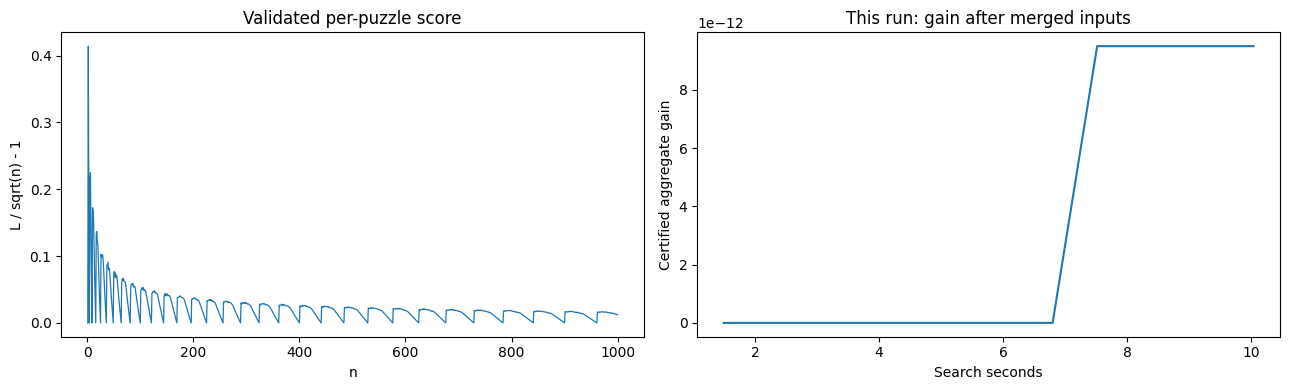

Ready: /workspace/work/notebook_run/submission.csv


In [10]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(details.n,details.score,lw=.9)
axes[0].set(xlabel='n',ylabel='L / sqrt(n) - 1',title='Validated per-puzzle score')
trace_path=RUN_DIR/'search_trace.csv'
if trace_path.exists() and trace_path.stat().st_size>2:
    trace=pd.read_csv(trace_path)
    if len(trace):
        axes[1].plot(trace.seconds.cumsum(),MERGED_START-trace.total)
        axes[1].set(xlabel='Search seconds',ylabel='Certified aggregate gain',title='This run: gain after merged inputs')
else:axes[1].text(.1,.5,'No search jobs requested',transform=axes[1].transAxes)
plt.tight_layout();plt.show()
print('Ready:',Path('submission.csv').resolve())

## Measured development results

| Stage | Total local score | Evidence |
|---|---:|---|
| Exact grid | 28.937669917 | Formula for all 1,000 counts |
| Imported coordinate witnesses and uploaded replay | 22.335187779071 | Floating estimate before construction propagation |
| After deletion, borders and tiling | 22.333522251194 | All 1,000 puzzles and 500,500 actual CSV rows accepted by the unchanged metric snapshot; no rejected puzzles |
| Short search integration run | 22.333522251184 | 15 jobs, all 10 operators exercised; about 16 seconds of search |
| Stronger supplied notebook | 22.298183371701 | Reported in the attachment after its public CSV merge; its complete merged CSV was not uploaded here |

The short search gained only about **9.5e-12**, which is not a meaningful competitive improvement. It verifies that the components run together and preserve feasibility; it does **not** demonstrate a breakthrough or beat the stronger supplied notebook. Longer runs and public-output ingestion need their own measured comparison. The default 7,200-second budget is configurable, and unmodified baseline poses reuse results from the full development validation only when their parsed bytes and metric hash match. Set `SIS_RECHECK_ALL=1` to recompute every certificate.

The Kaggle metadata carries the same public input version IDs as the supplied stronger notebook. Whether a particular import flow attaches them automatically depends on Kaggle; the explicit public-output refresh and Input scan provide the other loading paths. Source availability is never assumed in the recorded local score.


## Practical next experiments

1. Refresh public inputs, then run several independent seeds. Merge their
   CSVs per puzzle with this same validator. No single layout family dominates
   all 1,000 counts.
2. Compare equal wall budgets for `branch`, collective moves, and plain
   polishing using `search_trace.csv`. Keep operators that add certified gain;
   a complicated idea that produces no improvement earns no performance claim.
3. For larger campaigns, port the evaluated SAT objective and gradients to a
   batched GPU implementation with independent basins. This notebook does not
   include or claim to have tested that GPU port.
4. Explore full signed-distance rounded-square continuation as in the cited
   preprint; the implemented support surrogate is cheaper but less faithful.
   Keep the final square validator unchanged.

Better starts and larger budgets can help, but this remains a nonconvex
heuristic. No code here proves a packing globally optimal or guarantees a
leaderboard position.

## Credits, source status, and licences

- Original constructions and arrangements retain the authors credited in
  `source_provenance.json` and the pinned upstream certificate packets:
  Frits Göbel, Erich Friedman, Walter Trump, Robert Wainwright, David Ellsworth,
  David Cantrell, Thomas Schadt, Francisco Couzo, Evan Daniel, PingYou Ltd,
  Mykhailo Polkovskyi, and the other contributors recorded there.
- Exact atlas witness conversion: Evan Daniel's MIT repository. Its displayed
  Ellsworth-derived atlas material has separate authorship; no diagrams or
  SVG assets were copied here. The actual mathematical coordinate witnesses
  are credited through their source records.
- Uploaded replay: [Malyshevdanil, Neighbour Transfer + Squeeze](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-neighbour-transfer-squeeze),
  retaining its credits to the Fresh Records base, lightningv08, prvsiyan,
  kirilltym, and public packing contributors. Its search modules were audited;
  this notebook's engine was independently implemented, not copied from those
  modules. Replayed coordinates are labelled as inherited data.
- Public CSV refresh retains each input's path, notebook handle and file hash.
  All source credits of those notebooks continue to apply to inherited poses.
- The metric snapshot is Apache-2.0, supplied unchanged by the uploaded notebook:
  [metric source](https://www.kaggle.com/code/metric/squares-in-squares),
  [Apache-2.0 licence text](https://www.apache.org/licenses/LICENSE-2.0.txt).
  Reuse and modifications of the surrounding engine do not modify that metric.
- Research preprints and public computer-assisted result claims are attributed
  with their limitations; they are not silently promoted to peer-reviewed proof.

Evan Daniel repository licence, reproduced for the retained witness material:

```text
MIT License

Copyright (c) 2026 Evan Daniel

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.


```

The metric snapshot is distributed with the full Apache-2.0 licence below.

```text
                             Apache License
                       Version 2.0, January 2004
                    http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

  "License" shall mean the terms and conditions for use, reproduction,
  and distribution as defined by Sections 1 through 9 of this document.

  "Licensor" shall mean the copyright owner or entity authorized by
  the copyright owner that is granting the License.

  "Legal Entity" shall mean the union of the acting entity and all
  other entities that control, are controlled by, or are under common
  control with that entity. For the purposes of this definition,
  "control" means (i) the power, direct or indirect, to cause the
  direction or management of such entity, whether by contract or
  otherwise, or (ii) ownership of fifty percent (50%) or more of the
  outstanding shares, or (iii) beneficial ownership of such entity.

  "You" (or "Your") shall mean an individual or Legal Entity
  exercising permissions granted by this License.

  "Source" form shall mean the preferred form for making modifications,
  including but not limited to software source code, documentation
  source, and configuration files.

  "Object" form shall mean any form resulting from mechanical
  transformation or translation of a Source form, including but
  not limited to compiled object code, generated documentation,
  and conversions to other media types.

  "Work" shall mean the work of authorship, whether in Source or
  Object form, made available under the License, as indicated by a
  copyright notice that is included in or attached to the work
  (an example is provided in the Appendix below).

  "Derivative Works" shall mean any work, whether in Source or Object
  form, that is based on (or derived from) the Work and for which the
  editorial revisions, annotations, elaborations, or other modifications
  represent, as a whole, an original work of authorship. For the purposes
  of this License, Derivative Works shall not include works that remain
  separable from, or merely link (or bind by name) to the interfaces of,
  the Work and Derivative Works thereof.

  "Contribution" shall mean any work of authorship, including
  the original version of the Work and any modifications or additions
  to that Work or Derivative Works thereof, that is intentionally
  submitted to Licensor for inclusion in the Work by the copyright owner
  or by an individual or Legal Entity authorized to submit on behalf of
  the copyright owner. For the purposes of this definition, "submitted"
  means any form of electronic, verbal, or written communication sent
  to the Licensor or its representatives, including but not limited to
  communication on electronic mailing lists, source code control systems,
  and issue tracking systems that are managed by, or on behalf of, the
  Licensor for the purpose of discussing and improving the Work, but
  excluding communication that is conspicuously marked or otherwise
  designated in writing by the copyright owner as "Not a Contribution."

  "Contributor" shall mean Licensor and any individual or Legal Entity
  on behalf of whom a Contribution has been received by Licensor and
  subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
  this License, each Contributor hereby grants to You a perpetual,
  worldwide, non-exclusive, no-charge, royalty-free, irrevocable
  copyright license to reproduce, prepare Derivative Works of,
  publicly display, publicly perform, sublicense, and distribute the
  Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
  this License, each Contributor hereby grants to You a perpetual,
  worldwide, non-exclusive, no-charge, royalty-free, irrevocable
  (except as stated in this section) patent license to make, have made,
  use, offer to sell, sell, import, and otherwise transfer the Work,
  where such license applies only to those patent claims licensable
  by such Contributor that are necessarily infringed by their
  Contribution(s) alone or by combination of their Contribution(s)
  with the Work to which such Contribution(s) was submitted. If You
  institute patent litigation against any entity (including a
  cross-claim or counterclaim in a lawsuit) alleging that the Work
  or a Contribution incorporated within the Work constitutes direct
  or contributory patent infringement, then any patent licenses
  granted to You under this License for that Work shall terminate
  as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
  Work or Derivative Works thereof in any medium, with or without
  modifications, and in Source or Object form, provided that You
  meet the following conditions:

  (a) You must give any other recipients of the Work or
      Derivative Works a copy of this License; and

  (b) You must cause any modified files to carry prominent notices
      stating that You changed the files; and

  (c) You must retain, in the Source form of any Derivative Works
      that You distribute, all copyright, patent, trademark, and
      attribution notices from the Source form of the Work,
      excluding those notices that do not pertain to any part of
      the Derivative Works; and

  (d) If the Work includes a "NOTICE" text file as part of its
      distribution, then any Derivative Works that You distribute must
      include a readable copy of the attribution notices contained
      within such NOTICE file, excluding those notices that do not
      pertain to any part of the Derivative Works, in at least one
      of the following places: within a NOTICE text file distributed
      as part of the Derivative Works; within the Source form or
      documentation, if provided along with the Derivative Works; or,
      within a display generated by the Derivative Works, if and
      wherever such third-party notices normally appear. The contents
      of the NOTICE file are for informational purposes only and
      do not modify the License. You may add Your own attribution
      notices within Derivative Works that You distribute, alongside
      or as an addendum to the NOTICE text from the Work, provided
      that such additional attribution notices cannot be construed
      as modifying the License.

  You may add Your own copyright statement to Your modifications and
  may provide additional or different license terms and conditions
  for use, reproduction, or distribution of Your modifications, or
  for any such Derivative Works as a whole, provided Your use,
  reproduction, and distribution of the Work otherwise complies with
  the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
  any Contribution intentionally submitted for inclusion in the Work
  by You to the Licensor shall be under the terms and conditions of
  this License, without any additional terms or conditions.
  Notwithstanding the above, nothing herein shall supersede or modify
  the terms of any separate license agreement you may have executed
  with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
  names, trademarks, service marks, or product names of the Licensor,
  except as required for reasonable and customary use in describing the
  origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
  agreed to in writing, Licensor provides the Work (and each
  Contributor provides its Contributions) on an "AS IS" BASIS,
  WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
  implied, including, without limitation, any warranties or conditions
  of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
  PARTICULAR PURPOSE. You are solely responsible for determining the
  appropriateness of using or redistributing the Work and assume any
  risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
  whether in tort (including negligence), contract, or otherwise,
  unless required by applicable law (such as deliberate and grossly
  negligent acts) or agreed to in writing, shall any Contributor be
  liable to You for damages, including any direct, indirect, special,
  incidental, or consequential damages of any character arising as a
  result of this License or out of the use or inability to use the
  Work (including but not limited to damages for loss of goodwill,
  work stoppage, computer failure or malfunction, or any and all
  other commercial damages or losses), even if such Contributor
  has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
  the Work or Derivative Works thereof, You may choose to offer,
  and charge a fee for, acceptance of support, warranty, indemnity,
  or other liability obligations and/or rights consistent with this
  License. However, in accepting such obligations, You may act only
  on Your own behalf and on Your sole responsibility, not on behalf
  of any other Contributor, and only if You agree to indemnify,
  defend, and hold each Contributor harmless for any liability
  incurred by, or claims asserted against, such Contributor by reason
  of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

  To apply the Apache License to your work, attach the following
  boilerplate notice, with the fields enclosed by brackets "[]"
  replaced with your own identifying information. (Don't include
  the brackets!)  The text should be enclosed in the appropriate
  comment syntax for the file format. We also recommend that a
  file or class name and description of purpose be included on the
  same "printed page" as the copyright notice for easier
  identification within third-party archives.

   Copyright 2018 Kaggle Inc

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

   http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.


```

The original `sis_engine.py` implementation in this notebook is provided under the MIT licence:

```text
Copyright (c) 2026 the notebook authors

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```
This licence applies to the new engine; separately attributed metric and source
witness material retain their own licences and credits.
